# Phase 3: Cutoff Design, Leak-Free Feature Engineering & Target Construction

**Project:** Customer Intelligence Engine (RFM Segmentation + 90-Day CLV Regression)  
**Inputs:** `data/processed/sales_clean.parquet` & `data/processed/returns_clean.parquet`  
*(Note: `guest_transactions.parquet` and `admin_rows.parquet` are intentionally excluded from customer-level modeling.)*

---

## Core Architectural Decisions & Interview Defense

1. **Two Seasonally Aligned Cutoffs (`T_train` & `T_test`) with Strict Exclusive Boundaries:**
   - `T_train = 2010-09-10 00:00:00` $\rightarrow$ target window `[2010-09-10, 2010-12-09)`
   - `T_test  = 2011-09-10 00:00:00` $\rightarrow$ target window `[2011-09-10, 2011-12-09)`
   - **Why:** Both target windows span the exact same 90-day Sep–Dec Q4 period, eliminating seasonal shift between training and evaluation. Using `< T` for features and `[T, T + 90d)` for targets prevents temporal leakage and automatically excludes the partial final day (`2011-12-09`).
2. **Fixed Lookback Window ($L = 270$ days: `[T - 270d, T)`):**
   - **Why:** `T_train` only has ~283 days of prior history (`2009-12-01` to `2010-09-10`). If we used "all prior history", `T_train` features would aggregate ~9 months while `T_test` features would aggregate ~21 months, creating artificial covariate shift in cumulative metrics (`frequency`, `monetary`). A fixed 270-day lookback guarantees identical feature semantics across both cutoffs.
3. **Gross Sales Target (`target`) + Companion Targets (`target_net`, `target_active`):**
   - **Why:** `target` sums `TotalPrice` strictly from `sales_clean` in `[T, T + 90d)` (filling inactive eligible customers with `0`). Using gross sales avoids negative CLV regression targets and prevents returns of *pre-cutoff* orders occurring inside `[T, T + 90d)` from distorting future purchase intent. Returns are strictly used as **historical** features. `target_net` (sensitivity) and `target_active` (binary hurdle option) are stored alongside for downstream experimentation.
4. **Eligibility Rule:**
   - A customer is eligible at cutoff $T$ iff they have $\ge 1$ purchase row in `sales_clean` inside `[T - 270d, T)`. Customers with returns-only or no activity inside the lookback are excluded (documented as a cold-start scope boundary).
5. **No Q4 / Seasonality Flag:**
   - Both target windows fall in Sep–Dec, so a Q4 seasonality flag would be constant across both cutoffs (zero variance).

---

## Strict Scope (What This Notebook Does & Does NOT Do)
- **Allowed:** Feature engineering (`build_features`), target construction (`build_target`), leakage audits, feature EDA/drift analysis, descriptive RFM snapshot, and Parquet/module exports (`src/features.py`).
- **Strictly Excluded:** Feature scaling, log transforms, categorical encoding, `NaN` imputation (keep `NaN`s such as inter-purchase gaps for 1-invoice buyers and add binary flags instead), train/val splitting for models, or model training. All fitting-based transforms belong inside `sklearn` `Pipeline`s later.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

if "display" not in globals():
    try:
        from IPython.display import display
    except ImportError:
        display = print

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = PROCESSED_DIR / "features"

SALES_PATH = PROCESSED_DIR / "sales_clean.parquet"
RETURNS_PATH = PROCESSED_DIR / "returns_clean.parquet"

assert SALES_PATH.exists(), f"Missing {SALES_PATH}"
assert RETURNS_PATH.exists(), f"Missing {RETURNS_PATH}"

print(f"Project Root : {PROJECT_ROOT}")
print(f"Sales Input  : {SALES_PATH}")
print(f"Returns Input: {RETURNS_PATH}")

Project Root : c:\Users\mosa\Desktop\Projects\Customer-Intelligence-Engine
Sales Input  : data\processed\sales_clean.parquet
Returns Input: data\processed\returns_clean.parquet


## Step 0: Load Cleaned Tables & Sanity Check

### Why Sanity-Check Before Building Cutoffs?
Even though Phase 2 asserted data quality before writing Parquet files, verifying the loaded inputs at the start of Phase 3 protects against silent upstream changes:
1. Confirms exact column names and schema (`Customer ID` as nullable `Int64`, `InvoiceDate` as `datetime64`, `TotalPrice` as `float64`).
2. Confirms zero null `Customer ID`s and valid sign invariants (`Quantity > 0`, `Price > 0` in `sales_clean`; `Quantity < 0`, `Price > 0` in `returns_clean`).
3. Inspects the exact `InvoiceDate` min/max boundaries (verifying the partial final day `2011-12-09 12:50`) and unique customer counts before defining `T_train` and `T_test`.

In [2]:
sales_clean = pd.read_parquet(SALES_PATH)
returns_clean = pd.read_parquet(RETURNS_PATH)

# Sanity assertions on loaded Parquet contracts
assert sales_clean["Customer ID"].isna().sum() == 0, "Null Customer ID found in sales_clean!"
assert returns_clean["Customer ID"].isna().sum() == 0, "Null Customer ID found in returns_clean!"
assert (sales_clean["Quantity"] > 0).all() and (sales_clean["Price"] > 0).all(), "Invalid Quantity/Price in sales_clean!"
assert (returns_clean["Quantity"] < 0).all() and (returns_clean["Price"] > 0).all(), "Invalid Quantity/Price in returns_clean!"

print("=" * 70)
print("STEP 0 SUMMARY: INPUT SANITY CHECK")
print("=" * 70)
print(f"sales_clean shape   : {sales_clean.shape}")
print(f"returns_clean shape : {returns_clean.shape}")

print(f"\nsales_clean InvoiceDate range   : {sales_clean['InvoiceDate'].min()}  -->  {sales_clean['InvoiceDate'].max()}")
print(f"returns_clean InvoiceDate range : {returns_clean['InvoiceDate'].min()}  -->  {returns_clean['InvoiceDate'].max()}")

sales_custs = set(sales_clean["Customer ID"].unique())
returns_custs = set(returns_clean["Customer ID"].unique())
print(f"\nUnique customers in sales_clean   : {len(sales_custs):,}")
print(f"Unique customers in returns_clean : {len(returns_custs):,}")
print(f"Returns-only customers (no sales) : {len(returns_custs - sales_custs):,}")
print(f"Combined unique registered custs  : {len(sales_custs | returns_custs):,}")

print("\nNull counts in sales_clean:")
print(sales_clean.isna().sum())

print("\nColumn Dtypes (sales_clean):")
print(sales_clean.dtypes)

print("\n5 Sample Rows from sales_clean (Random Seed = 42):")
display(sales_clean.sample(5, random_state=42))

print("\n5 Sample Rows from returns_clean (Random Seed = 42):")
display(returns_clean.sample(5, random_state=42))

STEP 0 SUMMARY: INPUT SANITY CHECK
sales_clean shape   : (776593, 13)
returns_clean shape : (17585, 13)

sales_clean InvoiceDate range   : 2009-12-01 07:45:00  -->  2011-12-09 12:50:00
returns_clean InvoiceDate range : 2009-12-01 10:33:00  -->  2011-12-09 11:58:00

Unique customers in sales_clean   : 5,852
Unique customers in returns_clean : 2,443
Returns-only customers (no sales) : 23
Combined unique registered custs  : 5,875

Null counts in sales_clean:
Invoice            0
StockCode          0
Description        0
Quantity           0
InvoiceDate        0
Price              0
Customer ID        0
Country            0
source_sheet       0
is_cancellation    0
TotalPrice         0
invoice_date       0
year_month         0
dtype: int64

Column Dtypes (sales_clean):
Invoice                    string
StockCode                  string
Description                string
Quantity                    int64
InvoiceDate        datetime64[us]
Price                     float64
Customer ID         

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet,is_cancellation,TotalPrice,invoice_date,year_month
757201,579503,22699,ROSES REGENCY TEACUP AND SAUCER,4,2011-11-29 16:23:00,2.95,17097,Spain,Year 2010-2011,False,11.80,2011-11-29,2011-11
458697,546091,84978,HANGING HEART JAR T-LIGHT HOLDER,12,2011-03-09 11:53:00,1.25,14936,Channel Islands,Year 2010-2011,False,15.00,2011-03-09,2011-03
497366,550993,22384,LUNCH BAG PINK POLKADOT,10,2011-04-21 19:51:00,1.65,15810,United Kingdom,Year 2010-2011,False,16.50,2011-04-21,2011-04
164243,510993,21890,S/6 WOODEN SKITTLES IN COTTON BAG,6,2010-06-04 13:47:00,2.95,18206,United Kingdom,Year 2009-2010,False,17.70,2010-06-04,2010-06
274,489488,22086,PAPER CHAIN KIT 50'S CHRISTMAS,5,2009-12-01 10:59:00,2.95,17238,United Kingdom,Year 2009-2010,False,14.75,2009-12-01,2009-12



5 Sample Rows from returns_clean (Random Seed = 42):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet,is_cancellation,TotalPrice,invoice_date,year_month
3827,C508358,22488,NATURAL SLATE RECTANGLE CHALKBOARD,-3,2010-05-14 12:45:00,1.65,12523,France,Year 2009-2010,True,-4.95,2010-05-14,2010-05
1350,C495174,72753D,S/3 FLWR FAIRY SUMMER CANDLES,-8,2010-01-21 12:59:00,2.10,13901,United Kingdom,Year 2009-2010,True,-16.80,2010-01-21,2010-01
15672,C570828,90185C,BLACK DIAMANTE EXPANDABLE RING,-6,2011-10-12 13:15:00,4.25,14911,EIRE,Year 2010-2011,True,-25.50,2011-10-12,2011-10
11972,C551551,22356,CHARLOTTE BAG PINK POLKADOT,-2,2011-05-03 10:08:00,0.85,17841,United Kingdom,Year 2010-2011,True,-1.70,2011-05-03,2011-05
2281,C500724,22198,LARGE POPCORN HOLDER,-5,2010-03-09 15:44:00,1.65,14156,EIRE,Year 2009-2010,True,-8.25,2010-03-09,2010-03


## Step 1: Define Cutoffs, Fixed Lookback (`L = 270`), and Window Helper

### Why Two Cutoffs (`2010-09-10` & `2011-09-10`) + Fixed Lookback (`L = 270d`)?
1. **Eliminating Seasonal Shift:** In retail, Q4 (September–December) generates massive holiday surges compared to Q1–Q3. If we trained on Q2 and tested on Q4, the model would learn wrong baseline spend rates. Setting both `T_train = 2010-09-10` and `T_test = 2011-09-10` ensures **both** 90-day target windows cover the exact same Sep 10 – Dec 9 seasonal ramp.
2. **Preventing History-Length Distribution Shift (`L = 270` days):** At `T_train = 2010-09-10`, only ~283 days of history exist (`2009-12-01` onwards). Using an unbounded "all history" lookback would give `T_train` customers at most 9 months of cumulative spend/orders, while giving `T_test` customers 21 months — artificially inflating `frequency` and `monetary` at test time. Fixing $L = 270$ days guarantees identical feature scales across both cutoffs, and leaves a full 270 days observed (`2009-12-14` to `2010-09-10`).
3. **Exclusive Boundary & Partial Final Day Exclusion:** By defining features as `[T - 270d, T)` and targets as `[T, T + 90d)`, `T_test + 90d = 2011-12-09 00:00:00` automatically excludes the incomplete half-day on `2011-12-09` (which ends at `12:50`), ensuring both target windows cover an exact `90.0` full calendar days.
4. **No Q4 Seasonality Flag:** Because both cutoffs target Sep–Dec, any Q4 flag on the target window would be a constant (`1`) across every row and carry zero predictive information.

In [3]:
T_TRAIN = pd.Timestamp("2010-09-10 00:00:00")
T_TEST = pd.Timestamp("2011-09-10 00:00:00")
LOOKBACK_DAYS = 270
HORIZON_DAYS = 90

DATA_START = sales_clean["InvoiceDate"].min()
DATA_END = sales_clean["InvoiceDate"].max()

def get_window_bounds(
    cutoff: pd.Timestamp,
    lookback_days: int | None = LOOKBACK_DAYS,
    horizon_days: int = HORIZON_DAYS,
    data_start: pd.Timestamp = DATA_START,
) -> dict:
    '''Compute exact [lookback_start, cutoff) and [cutoff, target_end) window boundaries.'''
    cutoff = pd.Timestamp(cutoff)
    lookback_start = (
        cutoff - pd.Timedelta(days=lookback_days)
        if lookback_days is not None
        else pd.Timestamp(data_start)
    )
    target_end = cutoff + pd.Timedelta(days=horizon_days)
    return {
        "lookback_start": lookback_start,
        "cutoff": cutoff,
        "target_end": target_end,
        "lookback_days": (cutoff - lookback_start).days,
        "horizon_days": (target_end - cutoff).days,
    }

train_win = get_window_bounds(T_TRAIN, LOOKBACK_DAYS, HORIZON_DAYS)
test_win = get_window_bounds(T_TEST, LOOKBACK_DAYS, HORIZON_DAYS)

# Verify full lookback coverage and complete target windows strictly inside available data
for name, win in [("T_train", train_win), ("T_test", test_win)]:
    assert win["lookback_start"] >= DATA_START, f"{name} lookback_start {win['lookback_start']} precedes DATA_START {DATA_START}!"
    assert win["target_end"] < DATA_END, f"{name} target_end {win['target_end']} is not strictly before DATA_END {DATA_END}!"

# Summarize window dates and transaction row counts
window_rows = []
for name, win in [("T_train", train_win), ("T_test", test_win)]:
    lb_sales = sales_clean[
        (sales_clean["InvoiceDate"] >= win["lookback_start"]) & (sales_clean["InvoiceDate"] < win["cutoff"])
    ]
    tg_sales = sales_clean[
        (sales_clean["InvoiceDate"] >= win["cutoff"]) & (sales_clean["InvoiceDate"] < win["target_end"])
    ]
    window_rows.append({
        "split": name,
        "lookback_start": win["lookback_start"],
        "cutoff": win["cutoff"],
        "target_end": win["target_end"],
        "lookback_days": win["lookback_days"],
        "horizon_days": win["horizon_days"],
        "lookback_sales_rows": len(lb_sales),
        "target_sales_rows": len(tg_sales),
    })

windows_df = pd.DataFrame(window_rows)
partial_last_day_rows = int((sales_clean["InvoiceDate"] >= test_win["target_end"]).sum())

print("=" * 70)
print("STEP 1 SUMMARY: CUTOFFS & WINDOW BOUNDS VERIFIED")
print("=" * 70)
print(f"Data Min Timestamp : {DATA_START}")
print(f"Data Max Timestamp : {DATA_END}")
print(f"Partial final day rows (>= {test_win['target_end']}) excluded automatically: {partial_last_day_rows:,}")
display(windows_df)

print("\n5 Sample Sales Rows Immediately Preceding T_test Cutoff (verifying < T boundary):")
display(sales_clean[sales_clean["InvoiceDate"] < T_TEST].sort_values("InvoiceDate").tail(5))

STEP 1 SUMMARY: CUTOFFS & WINDOW BOUNDS VERIFIED
Data Min Timestamp : 2009-12-01 07:45:00
Data Max Timestamp : 2011-12-09 12:50:00
Partial final day rows (>= 2011-12-09 00:00:00) excluded automatically: 604


,split,lookback_start,cutoff,target_end,lookback_days,horizon_days,lookback_sales_rows,target_sales_rows
0,T_train,2009-12-14,2010-09-10,2010-12-09,270,90,231196,145965
1,T_test,2010-12-14,2011-09-10,2011-12-09,270,90,214769,157659



5 Sample Sales Rows Immediately Preceding T_test Cutoff (verifying < T boundary):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet,is_cancellation,TotalPrice,invoice_date,year_month
618306,566220,23247,BISCUIT TIN 50'S CHRISTMAS,36,2011-09-09 15:53:00,2.49,15251,United Kingdom,Year 2010-2011,False,89.64,2011-09-09,2011-09
618305,566220,22942,CHRISTMAS LIGHTS 10 SANTAS,24,2011-09-09 15:53:00,7.65,15251,United Kingdom,Year 2010-2011,False,183.60,2011-09-09,2011-09
618328,566220,22980,PANTRY SCRUBBING BRUSH,48,2011-09-09 15:53:00,1.45,15251,United Kingdom,Year 2010-2011,False,69.60,2011-09-09,2011-09
618316,566220,22950,36 DOILIES VINTAGE CHRISTMAS,60,2011-09-09 15:53:00,1.45,15251,United Kingdom,Year 2010-2011,False,87.00,2011-09-09,2011-09
618329,566220,22622,BOX OF VINTAGE ALPHABET BLOCKS,6,2011-09-09 15:53:00,11.95,15251,United Kingdom,Year 2010-2011,False,71.70,2011-09-09,2011-09


## Step 2: Eligible Customers Audit (`L = 270` Days)

### Why Strictly Define Eligibility Before Engineering Features?
At any cutoff $T$, registered customers fall into distinct historical states:
1. **Eligible (`sales` in `[T - 270d, T)`):** Purchased at least once in the fixed 270-day lookback. All RFM and behavioral features are cleanly defined over the exact same 9-month horizon.
2. **Excluded — Returns-Only in Lookback:** Had cancellation rows in `[T - 270d, T)` without any positive sale inside the lookback (recency/monetary for sales would be undefined).
3. **Excluded — Outside Lookback (`< T - 270d`):** Purchased before `T - 270d` (older/lapsed accounts), with zero sales or returns inside `[T - 270d, T)`.
4. **Cold-Start (New in `[T, T + 90d)`):** First ever transaction happens *after* cutoff $T$; impossible to predict at $T$ from transaction logs alone (known scope boundary).

Evaluating the size of Group 3 (`Outside Lookback`) and checking how often they buy in `[T, T + 90d)` tells us whether `L = 270` captures the active population cleanly.

In [4]:
def audit_eligibility(
    sales_df: pd.DataFrame,
    returns_df: pd.DataFrame,
    cutoff: pd.Timestamp,
    lookback_days: int = LOOKBACK_DAYS,
    horizon_days: int = HORIZON_DAYS,
) -> tuple[dict, pd.DataFrame]:
    '''Audit eligible vs excluded customers at cutoff T and inspect excluded behavior.'''
    win = get_window_bounds(cutoff, lookback_days, horizon_days)
    lb_start, t_cut, tg_end = win["lookback_start"], win["cutoff"], win["target_end"]

    # Historical populations strictly before cutoff T
    sales_before = sales_df[sales_df["InvoiceDate"] < t_cut]
    returns_before = returns_df[returns_df["InvoiceDate"] < t_cut]
    all_before_ids = set(sales_before["Customer ID"]).union(set(returns_before["Customer ID"]))

    # Inside [T - L, T)
    sales_lb = sales_before[sales_before["InvoiceDate"] >= lb_start]
    returns_lb = returns_before[returns_before["InvoiceDate"] >= lb_start]

    eligible_ids = set(sales_lb["Customer ID"].unique())
    returns_lb_ids = set(returns_lb["Customer ID"].unique())
    returns_only_lb_ids = returns_lb_ids - eligible_ids

    # Outside lookback (< T - L) with zero activity inside [T - L, T)
    outside_lookback_ids = all_before_ids - eligible_ids - returns_only_lb_ids
    assert len(eligible_ids) + len(returns_only_lb_ids) + len(outside_lookback_ids) == len(all_before_ids)

    # Target window activity check (audit only — never used as features)
    tg_sales = sales_df[(sales_df["InvoiceDate"] >= t_cut) & (sales_df["InvoiceDate"] < tg_end)]
    tg_ids = set(tg_sales["Customer ID"].unique())
    cold_start_ids = tg_ids - all_before_ids

    # Build per-customer eligibility summary table for excluded customers
    excluded_rows = []
    for cid in sorted(returns_only_lb_ids | outside_lookback_ids):
        reason = "returns_only_in_lookback" if cid in returns_only_lb_ids else "no_activity_in_lookback"
        excluded_rows.append({
            "Customer ID": cid,
            "exclusion_reason": reason,
            "bought_in_target_90d": cid in tg_ids,
        })
    excluded_df = pd.DataFrame(excluded_rows)

    summary = {
        "cutoff": t_cut.strftime("%Y-%m-%d"),
        "registered_before_T": len(all_before_ids),
        "eligible_customers": len(eligible_ids),
        "eligible_pct_of_before_T": round(len(eligible_ids) / len(all_before_ids) * 100, 2),
        "excluded_total": len(returns_only_lb_ids) + len(outside_lookback_ids),
        "excluded_returns_only_lb": len(returns_only_lb_ids),
        "excluded_outside_lookback": len(outside_lookback_ids),
        "eligible_bought_in_target": len(eligible_ids & tg_ids),
        "excluded_bought_in_target": len((returns_only_lb_ids | outside_lookback_ids) & tg_ids),
        "cold_start_in_target": len(cold_start_ids),
    }
    return summary, excluded_df

train_elig_summary, train_excluded_df = audit_eligibility(sales_clean, returns_clean, T_TRAIN)
test_elig_summary, test_excluded_df = audit_eligibility(sales_clean, returns_clean, T_TEST)

elig_report_df = pd.DataFrame([train_elig_summary, test_elig_summary])

print("=" * 70)
print("STEP 2 SUMMARY: ELIGIBILITY AUDIT (L = 270 DAYS)")
print("=" * 70)
display(elig_report_df)

print("\nT_train Excluded Customer Breakdown:")
print(train_excluded_df.groupby(["exclusion_reason", "bought_in_target_90d"]).size())

print("\nT_test Excluded Customer Breakdown:")
print(test_excluded_df.groupby(["exclusion_reason", "bought_in_target_90d"]).size())

print("\n5 Sample Excluded Customers at T_test (with target reactivation audit):")
display(test_excluded_df.sample(5, random_state=42))

STEP 2 SUMMARY: ELIGIBILITY AUDIT (L = 270 DAYS)


,cutoff,registered_before_T,eligible_customers,eligible_pct_of_before_T,excluded_total,excluded_returns_only_lb,excluded_outside_lookback,eligible_bought_in_target,excluded_bought_in_target,cold_start_in_target
0,2010-09-10,3383,3228,95.42,155,26,129,1885,53,922
1,2011-09-10,5280,3224,61.06,2056,33,2023,1862,426,594



T_train Excluded Customer Breakdown:
exclusion_reason          bought_in_target_90d
no_activity_in_lookback   False                   88
                          True                    41
returns_only_in_lookback  False                   14
                          True                    12
dtype: int64

T_test Excluded Customer Breakdown:
exclusion_reason          bought_in_target_90d
no_activity_in_lookback   False                   1610
                          True                     413
returns_only_in_lookback  False                     20
                          True                      13
dtype: int64

5 Sample Excluded Customers at T_test (with target reactivation audit):


,Customer ID,exclusion_reason,bought_in_target_90d
184,13007,no_activity_in_lookback,False
1724,17359,no_activity_in_lookback,True
251,13205,no_activity_in_lookback,False
1121,15770,no_activity_in_lookback,False
1486,16741,no_activity_in_lookback,False


## Step 3: Feature Design Review (Before Implementation)

### Why Review Risks & Feature Contracts First?
Every feature below is computed **strictly** inside `[T - 270d, T)` (never touching `InvoiceDate >= T`). Before coding `build_features()`, we inspect:
1. **Proposed Feature Catalog (26 Features Across 6 Groups)**:
   - **Core RFM (`3`)**: `recency_days`, `frequency`, `monetary`
   - **Purchase Behavior (`6`)**: `aov`, `avg_items_per_invoice`, `avg_unit_price`, `n_unique_products`, `n_active_months`, `n_active_weeks`
   - **Customer Timing (`4`)**: `tenure_days_in_window`, `is_tenure_at_edge`, `mean_interpurchase_days` (`NaN` if 1 invoice — *not imputed here*), `is_single_invoice`
   - **Recent Momentum / Trend (`7`)**: `spend_last_30d`, `spend_last_60d`, `spend_last_90d`, `invoices_last_30d`, `invoices_last_60d`, `invoices_last_90d`, `spend_last_90d_ratio`
   - **Historical Returns (`4`)**: `return_invoice_count`, `return_value_abs`, `return_value_ratio`, `return_rate`
   - **Geography (`2`)**: `is_uk`, `country` (most recent country at `cutoff`, keeping `'Unspecified'` explicit)

2. **Risky Features & Why We Still Keep Them (Interview Defense)**:
   - **Collinearity Risk (`monetary` vs. `spend_last_30d`/`60d`/`90d`, `frequency` vs. `invoices_last_*` / `n_active_weeks`, `monetary = frequency * aov`)**:
     - *Why risky?* Unregularized linear models (OLS) will suffer from high VIF and unstable weights if fed nested cumulative windows simultaneously.
     - *Why keep them?* Tree-based ensembles (LightGBM, XGBoost, CatBoost, Random Forest) handle collinear features effortlessly and actually benefit from explicit momentum features (`spend_last_90d`, `spend_last_90d_ratio`) to separate accelerating VIPs from cooling buyers. For linear baselines (Ridge/Lasso/ElasticNet) later, regularization or explicit feature subsets inside sklearn `Pipeline`s will manage collinearity.
   - **Left-Censored `tenure_days_in_window`**:
     - *Why risky?* Because `L = 270` days cuts off older history, a loyal 2-year buyer and a customer acquired 268 days before $T$ can look identical at `tenure_days_in_window ≈ 270`.
     - *Why keep it + add `is_tenure_at_edge`?* Within-window tenure separates genuinely brand-new buyers (`tenure = 15d`) from established ones (`tenure = 250d`), while `is_tenure_at_edge` (`tenure >= lookback_days - 7`) explicitly flags accounts whose first in-window purchase occurred right at the left boundary (before the Dec holiday closure).
   - **Zero-Variance Features Excluded by Design**:
     - No Q4/seasonality flag is added because both `T_train` and `T_test` cover identical Sep–Dec target windows.

In [5]:
feature_catalog = [
    # Core RFM
    ("recency_days", "Core RFM", "(T - last_purchase_dt) in days", "Captures how recently the customer purchased; primary churn/decay predictor"),
    ("frequency", "Core RFM", "nunique(Invoice) in sales [T-L, T)", "Measures repeat engagement and habit strength"),
    ("monetary", "Core RFM", "sum(TotalPrice) in sales [T-L, T)", "Captures total historical gross spending power over the 270d window"),
    # Behavior
    ("aov", "Behavior", "monetary / frequency", "Separates bulk wholesale basket buyers from frequent small buyers"),
    ("avg_items_per_invoice", "Behavior", "sum(Quantity) / frequency", "Distinguishes high-volume pack buyers from high-price single-item buyers"),
    ("avg_unit_price", "Behavior", "monetary / sum(Quantity)", "Quantity-weighted unit price reflecting product tier preference"),
    ("n_unique_products", "Behavior", "nunique(StockCode) in sales [T-L, T)", "Breadth of catalog adoption; multi-SKU buyers retain better"),
    ("n_active_months", "Behavior", "nunique(year_month) in sales [T-L, T)", "Measures spread of purchasing across calendar months vs one-off spikes"),
    ("n_active_weeks", "Behavior", "nunique(ISO year-week) in sales [T-L, T)", "Finer-grained purchase regularity across the 39-week lookback"),
    # Timing
    ("tenure_days_in_window", "Timing", "(T - first_purchase_dt) in days (censored at L)", "Age within the lookback window; distinguishes brand-new vs established buyers"),
    ("is_tenure_at_edge", "Timing", "1 if tenure_days_in_window >= L - 7 else 0", "Flags customers hitting the left lookback boundary (left-censoring indicator)"),
    ("mean_interpurchase_days", "Timing", "(last_inv_dt - first_inv_dt) / (frequency - 1); NaN if freq==1", "Natural reorder cadence; left as NaN for single-invoice buyers (no fake 0 imputation)"),
    ("is_single_invoice", "Timing", "1 if frequency == 1 else 0", "Explicit indicator complementing NaN in mean_interpurchase_days"),
    # Recent Trend
    ("spend_last_30d", "Recent Trend", "sum(TotalPrice) in [T-30d, T)", "Captures immediate short-term spending momentum"),
    ("spend_last_60d", "Recent Trend", "sum(TotalPrice) in [T-60d, T)", "Captures medium-term spending trajectory before cutoff"),
    ("spend_last_90d", "Recent Trend", "sum(TotalPrice) in [T-90d, T)", "Matches the 90-day prediction horizon length directly prior to T"),
    ("invoices_last_30d", "Recent Trend", "nunique(Invoice) in [T-30d, T)", "Captures recent order cadence acceleration or slowdown"),
    ("invoices_last_60d", "Recent Trend", "nunique(Invoice) in [T-60d, T)", "Captures 2-month order count before cutoff"),
    ("invoices_last_90d", "Recent Trend", "nunique(Invoice) in [T-90d, T)", "Matches 90-day future horizon order frequency directly prior to T"),
    ("spend_last_90d_ratio", "Recent Trend", "spend_last_90d / monetary", "Measures spend recency share (1.0 = all spend is recent vs 0.0 = cooling off)"),
    # Returns (history only)
    ("return_invoice_count", "Returns", "nunique(Invoice) in returns [T-L, T)", "Count of historical cancellation/credit invoices"),
    ("return_value_abs", "Returns", "abs(sum(TotalPrice)) in returns [T-L, T)", "Total historical refunded value in GBP"),
    ("return_value_ratio", "Returns", "return_value_abs / monetary", "Fraction of gross sales reversed by returns (risk / friction signal)"),
    ("return_rate", "Returns", "return_invoice_count / (frequency + return_invoice_count)", "Share of total customer invoices that ended in cancellation"),
    # Geography
    ("is_uk", "Geography", "1 if most recent Country == 'United Kingdom' else 0", "Domestic vs international wholesale/export shipping behavior"),
    ("country", "Geography", "Most recent Country at T (keeps 'Unspecified' explicit)", "Raw country category for downstream Pipeline encoding"),
]

catalog_df = pd.DataFrame(feature_catalog, columns=["feature", "group", "definition", "interview_reasoning"])

# Pre-implementation edge-case diagnostic across both lookbacks
edge_stats = []
for name, cutoff in [("T_train", T_TRAIN), ("T_test", T_TEST)]:
    lb_s = sales_clean[(sales_clean["InvoiceDate"] >= cutoff - pd.Timedelta(days=LOOKBACK_DAYS)) & (sales_clean["InvoiceDate"] < cutoff)]
    g = lb_s.groupby("Customer ID")
    tenure = (cutoff - g["InvoiceDate"].min()).dt.total_seconds() / 86400.0
    freq = g["Invoice"].nunique()
    n_cnt = g["Country"].nunique()
    edge_stats.append({
        "split": name,
        "eligible_customers": len(freq),
        "single_invoice_pct": round((freq == 1).mean() * 100, 2),
        "tenure_at_edge_7d_count": int((tenure >= LOOKBACK_DAYS - 7).sum()),
        "multi_country_customers": int((n_cnt > 1).sum()),
    })

print("=" * 70)
print("STEP 3 SUMMARY: PROPOSED FEATURE CATALOG (26 FEATURES)")
print("=" * 70)
print(f"Total proposed features: {len(catalog_df)}")
print(catalog_df["group"].value_counts())

print("\nPre-Implementation Edge-Case Stats Across Lookbacks:")
display(pd.DataFrame(edge_stats))

print("\nComplete Feature Catalog (Review & Approve Before Step 4):")
with pd.option_context("display.max_rows", 35, "display.max_colwidth", 90):
    display(catalog_df)

print("\n5 Sample Catalog Entries:")
display(catalog_df.head(5))

STEP 3 SUMMARY: PROPOSED FEATURE CATALOG (26 FEATURES)
Total proposed features: 26
group
Recent Trend    7
Behavior        6
Timing          4
Returns         4
Core RFM        3
Geography       2
Name: count, dtype: int64

Pre-Implementation Edge-Case Stats Across Lookbacks:


,split,eligible_customers,single_invoice_pct,tenure_at_edge_7d_count,multi_country_customers
0,T_train,3228,39.96,358,2
1,T_test,3224,41.25,316,6



Complete Feature Catalog (Review & Approve Before Step 4):


,feature,group,definition,interview_reasoning
0,recency_days,Core RFM,(T - last_purchase_dt) in days,Captures how recently the customer purchased; primary churn/decay predictor
1,frequency,Core RFM,"nunique(Invoice) in sales [T-L, T)",Measures repeat engagement and habit strength
2,monetary,Core RFM,"sum(TotalPrice) in sales [T-L, T)",Captures total historical gross spending power over the 270d window
3,aov,Behavior,monetary / frequency,Separates bulk wholesale basket buyers from frequent small buyers
4,avg_items_per_invoice,Behavior,sum(Quantity) / frequency,Distinguishes high-volume pack buyers from high-price single-item buyers
5,avg_unit_price,Behavior,monetary / sum(Quantity),Quantity-weighted unit price reflecting product tier preference
6,n_unique_products,Behavior,"nunique(StockCode) in sales [T-L, T)",Breadth of catalog adoption; multi-SKU buyers retain better
7,n_active_months,Behavior,"nunique(year_month) in sales [T-L, T)",Measures spread of purchasing across calendar months vs one-off spikes
8,n_active_weeks,Behavior,"nunique(ISO year-week) in sales [T-L, T)",Finer-grained purchase regularity across the 39-week lookback
9,tenure_days_in_window,Timing,(T - first_purchase_dt) in days (censored at L),Age within the lookback window; distinguishes brand-new vs established buyers



5 Sample Catalog Entries:


,feature,group,definition,interview_reasoning
0,recency_days,Core RFM,(T - last_purchase_dt) in days,Captures how recently the customer purchased; ...
1,frequency,Core RFM,"nunique(Invoice) in sales [T-L, T)",Measures repeat engagement and habit strength
2,monetary,Core RFM,"sum(TotalPrice) in sales [T-L, T)",Captures total historical gross spending power...
3,aov,Behavior,monetary / frequency,Separates bulk wholesale basket buyers from fr...
4,avg_items_per_invoice,Behavior,sum(Quantity) / frequency,Distinguishes high-volume pack buyers from hig...


## Step 4: Implement & Unit-Test `build_features`

### Why Unit-Test Feature Logic on a Hand-Crafted Synthetic Dataset First?
Aggregate pandas logic can fail silently through subtle bugs:
- **Off-by-one boundary leaks**: using `<= cutoff` instead of `< cutoff` leaks transactions occurring at midnight on cutoff day.
- **Wrong denominator**: dividing by line count instead of unique invoice count for `aov` or `return_rate`.
- **Silent `NaN` filling**: replacing `NaN` in `mean_interpurchase_days` for single-invoice customers with `0` falsely implies they reorder every `0` days!

By building a reusable `build_features(sales, returns, cutoff, lookback_days=270)` function containing **internal temporal assertions** and testing it against exact hand-calculated expectations (including boundary rows, outside-lookback rows, returns-only customers, single-invoice `NaN`s, and `lookback_days=None`), we prove correctness before generating `X_train` and `X_test`.

In [6]:
FEATURE_COLUMNS = [
    "recency_days", "frequency", "monetary",
    "aov", "avg_items_per_invoice", "avg_unit_price",
    "n_unique_products", "n_active_months", "n_active_weeks",
    "tenure_days_in_window", "is_tenure_at_edge",
    "mean_interpurchase_days", "is_single_invoice",
    "spend_last_30d", "spend_last_60d", "spend_last_90d",
    "invoices_last_30d", "invoices_last_60d", "invoices_last_90d",
    "spend_last_90d_ratio",
    "return_invoice_count", "return_value_abs", "return_value_ratio", "return_rate",
    "is_uk", "country",
]

def build_features(
    sales: pd.DataFrame,
    returns: pd.DataFrame,
    cutoff: pd.Timestamp | str,
    lookback_days: int | None = 270,
) -> pd.DataFrame:
    '''Build customer-level features strictly from [cutoff - lookback_days, cutoff).

    When lookback_days is None, uses all history strictly before cutoff (for descriptive segmentation).
    Returns a DataFrame indexed by Customer ID with NaNs intentionally preserved (e.g. single-invoice gaps).
    '''
    cutoff_ts = pd.Timestamp(cutoff)
    lb_start = cutoff_ts - pd.Timedelta(days=lookback_days) if lookback_days is not None else None

    if lb_start is not None:
        s_win = sales[(sales["InvoiceDate"] >= lb_start) & (sales["InvoiceDate"] < cutoff_ts)].copy()
        r_win = returns[(returns["InvoiceDate"] >= lb_start) & (returns["InvoiceDate"] < cutoff_ts)].copy()
    else:
        s_win = sales[sales["InvoiceDate"] < cutoff_ts].copy()
        r_win = returns[returns["InvoiceDate"] < cutoff_ts].copy()

    # Global Rule 3: Mandatory internal temporal boundary assertions
    if len(s_win) > 0:
        assert s_win["InvoiceDate"].max() < cutoff_ts, "TEMPORAL LEAKAGE: sales >= cutoff detected inside build_features!"
        if lb_start is not None:
            assert s_win["InvoiceDate"].min() >= lb_start, "WINDOW VIOLATION: sales older than cutoff - lookback_days detected!"
    if len(r_win) > 0:
        assert r_win["InvoiceDate"].max() < cutoff_ts, "TEMPORAL LEAKAGE: returns >= cutoff detected inside build_features!"
        if lb_start is not None:
            assert r_win["InvoiceDate"].min() >= lb_start, "WINDOW VIOLATION: returns older than cutoff - lookback_days detected!"

    if len(s_win) == 0:
        empty_df = pd.DataFrame(columns=FEATURE_COLUMNS)
        empty_df.index.name = "Customer ID"
        return empty_df

    # Helper column for active ISO weeks inside window
    s_win["_year_week"] = s_win["InvoiceDate"].dt.to_period("W")

    # Sort chronologically for deterministic latest Country lookup
    s_sorted = s_win.sort_values(["Customer ID", "InvoiceDate", "Invoice"])
    grouped = s_sorted.groupby("Customer ID")

    # Core RFM + Behavior + Geography
    first_dt = grouped["InvoiceDate"].min()
    last_dt = grouped["InvoiceDate"].max()
    frequency = grouped["Invoice"].nunique().astype("int64")
    monetary = grouped["TotalPrice"].sum().astype("float64")
    total_qty = grouped["Quantity"].sum().astype("float64")

    recency_days = (cutoff_ts - last_dt).dt.total_seconds() / 86400.0
    tenure_days_in_window = (cutoff_ts - first_dt).dt.total_seconds() / 86400.0
    is_tenure_at_edge = (
        (tenure_days_in_window >= (lookback_days - 7)).astype("int64")
        if lookback_days is not None
        else pd.Series(0, index=frequency.index, dtype="int64")
    )

    # Invoice-level span for mean interpurchase gap (NaN when frequency == 1)
    inv_span_days = (last_dt - first_dt).dt.total_seconds() / 86400.0
    mean_interpurchase_days = np.where(frequency > 1, inv_span_days / (frequency - 1), np.nan)
    is_single_invoice = (frequency == 1).astype("int64")

    latest_country = grouped["Country"].last().astype("string")
    is_uk = (latest_country == "United Kingdom").astype("int64")

    feat = pd.DataFrame(index=frequency.index)
    feat.index.name = "Customer ID"

    feat["recency_days"] = recency_days.astype("float64")
    feat["frequency"] = frequency
    feat["monetary"] = monetary
    feat["aov"] = monetary / frequency
    feat["avg_items_per_invoice"] = total_qty / frequency
    feat["avg_unit_price"] = monetary / total_qty
    feat["n_unique_products"] = grouped["StockCode"].nunique().astype("int64")
    feat["n_active_months"] = grouped["year_month"].nunique().astype("int64")
    feat["n_active_weeks"] = grouped["_year_week"].nunique().astype("int64")

    feat["tenure_days_in_window"] = tenure_days_in_window.astype("float64")
    feat["is_tenure_at_edge"] = is_tenure_at_edge
    feat["mean_interpurchase_days"] = pd.Series(mean_interpurchase_days, index=frequency.index, dtype="float64")
    feat["is_single_invoice"] = is_single_invoice

    # Recent trend sub-windows: 30d, 60d, 90d
    for w in (30, 60, 90):
        sub_start = cutoff_ts - pd.Timedelta(days=w)
        s_sub = s_win[s_win["InvoiceDate"] >= sub_start]
        if len(s_sub) > 0:
            sub_g = s_sub.groupby("Customer ID")
            spend_w = sub_g["TotalPrice"].sum().reindex(feat.index, fill_value=0.0).astype("float64")
            inv_w = sub_g["Invoice"].nunique().reindex(feat.index, fill_value=0).astype("int64")
        else:
            spend_w = pd.Series(0.0, index=feat.index, dtype="float64")
            inv_w = pd.Series(0, index=feat.index, dtype="int64")
        feat[f"spend_last_{w}d"] = spend_w
        feat[f"invoices_last_{w}d"] = inv_w

    feat["spend_last_90d_ratio"] = feat["spend_last_90d"] / feat["monetary"]

    # Historical returns inside [T - L, T)
    if len(r_win) > 0:
        r_g = r_win.groupby("Customer ID")
        ret_inv_cnt = r_g["Invoice"].nunique().reindex(feat.index, fill_value=0).astype("int64")
        ret_val_abs = r_g["TotalPrice"].sum().abs().reindex(feat.index, fill_value=0.0).astype("float64")
    else:
        ret_inv_cnt = pd.Series(0, index=feat.index, dtype="int64")
        ret_val_abs = pd.Series(0.0, index=feat.index, dtype="float64")

    feat["return_invoice_count"] = ret_inv_cnt
    feat["return_value_abs"] = ret_val_abs
    feat["return_value_ratio"] = ret_val_abs / feat["monetary"]
    feat["return_rate"] = ret_inv_cnt / (feat["frequency"] + ret_inv_cnt)

    feat["is_uk"] = is_uk
    feat["country"] = latest_country

    return feat[FEATURE_COLUMNS]


# =====================================================================
# Unit Test on Tiny Hand-Made DataFrame with Known Exact Answers
# =====================================================================
test_cutoff = pd.Timestamp("2020-07-01 00:00:00")
toy_sales = pd.DataFrame([
    # Cust 101: row BEFORE lb_start (2019-10-05) -> MUST be excluded when lookback_days=270
    {"Invoice": "900", "StockCode": "A0", "Quantity": 100, "InvoiceDate": "2019-09-01 00:00:00", "Price": 10.0, "Customer ID": 101, "Country": "United Kingdom", "year_month": "2019-09"},
    # Cust 101: in-window purchases (211d and 20d before cutoff)
    {"Invoice": "1001", "StockCode": "A1", "Quantity": 2, "InvoiceDate": "2019-12-03 00:00:00", "Price": 10.0, "Customer ID": 101, "Country": "United Kingdom", "year_month": "2019-12"},
    {"Invoice": "1002", "StockCode": "A2", "Quantity": 3, "InvoiceDate": "2020-06-11 00:00:00", "Price": 20.0, "Customer ID": 101, "Country": "United Kingdom", "year_month": "2020-06"},
    # Cust 101: row AT exact cutoff -> MUST be excluded (strict < cutoff)
    {"Invoice": "1004", "StockCode": "A1", "Quantity": 50, "InvoiceDate": "2020-07-01 00:00:00", "Price": 10.0, "Customer ID": 101, "Country": "United Kingdom", "year_month": "2020-07"},
    # Cust 102: single invoice at left window edge (267d before cutoff -> >= 263d)
    {"Invoice": "1005", "StockCode": "B1", "Quantity": 4, "InvoiceDate": "2019-10-08 00:00:00", "Price": 5.0, "Customer ID": 102, "Country": "France", "year_month": "2019-10"},
])
toy_sales["InvoiceDate"] = pd.to_datetime(toy_sales["InvoiceDate"])
toy_sales["TotalPrice"] = toy_sales["Quantity"] * toy_sales["Price"]

toy_returns = pd.DataFrame([
    # Cust 101: return inside lookback
    {"Invoice": "C1003", "StockCode": "A2", "Quantity": -1, "InvoiceDate": "2020-06-21 00:00:00", "Price": 20.0, "Customer ID": 101, "Country": "United Kingdom", "year_month": "2020-06"},
    # Cust 103: returns-only customer inside lookback -> MUST NOT appear in eligible features
    {"Invoice": "C1006", "StockCode": "B1", "Quantity": -2, "InvoiceDate": "2020-05-01 00:00:00", "Price": 5.0, "Customer ID": 103, "Country": "France", "year_month": "2020-05"},
])
toy_returns["InvoiceDate"] = pd.to_datetime(toy_returns["InvoiceDate"])
toy_returns["TotalPrice"] = toy_returns["Quantity"] * toy_returns["Price"]

toy_feat = build_features(toy_sales, toy_returns, cutoff=test_cutoff, lookback_days=270)
assert list(toy_feat.index) == [101, 102], f"Expected [101, 102], got {list(toy_feat.index)}"

# Assertions for Cust 101
c101 = toy_feat.loc[101]
assert np.isclose(c101["recency_days"], 20.0)
assert c101["frequency"] == 2
assert np.isclose(c101["monetary"], 80.0)
assert np.isclose(c101["aov"], 40.0)
assert np.isclose(c101["avg_items_per_invoice"], 2.5)
assert np.isclose(c101["avg_unit_price"], 16.0)
assert c101["n_unique_products"] == 2
assert c101["n_active_months"] == 2
assert c101["n_active_weeks"] == 2
assert np.isclose(c101["tenure_days_in_window"], 211.0)
assert c101["is_tenure_at_edge"] == 0
assert np.isclose(c101["mean_interpurchase_days"], 191.0)
assert c101["is_single_invoice"] == 0
assert np.isclose(c101["spend_last_30d"], 60.0)
assert np.isclose(c101["spend_last_90d_ratio"], 0.75)
assert c101["return_invoice_count"] == 1
assert np.isclose(c101["return_value_abs"], 20.0)
assert np.isclose(c101["return_value_ratio"], 0.25)
assert np.isclose(c101["return_rate"], 1 / 3)
assert c101["is_uk"] == 1 and c101["country"] == "United Kingdom"

# Assertions for Cust 102 (single invoice, edge-censored, France)
c102 = toy_feat.loc[102]
assert np.isclose(c102["recency_days"], 267.0)
assert c102["frequency"] == 1
assert np.isclose(c102["monetary"], 20.0)
assert c102["is_tenure_at_edge"] == 1
assert np.isnan(c102["mean_interpurchase_days"])
assert c102["is_single_invoice"] == 1
assert np.isclose(c102["spend_last_90d"], 0.0)
assert c102["return_invoice_count"] == 0 and np.isclose(c102["return_rate"], 0.0)
assert c102["is_uk"] == 0 and c102["country"] == "France"

# Also verify lookback_days=None mode includes Cust 101's 2019-09-01 order
toy_full = build_features(toy_sales, toy_returns, cutoff=test_cutoff, lookback_days=None)
assert toy_full.loc[101, "frequency"] == 3 and np.isclose(toy_full.loc[101, "monetary"], 1080.0)
assert toy_full.loc[102, "is_tenure_at_edge"] == 0

print("UNIT TEST PASSED: All hand-crafted assertions for build_features succeeded!")

# =====================================================================
# Run build_features for T_train and T_test
# =====================================================================
X_train_feat = build_features(sales_clean, returns_clean, cutoff=T_TRAIN, lookback_days=LOOKBACK_DAYS)
X_test_feat = build_features(sales_clean, returns_clean, cutoff=T_TEST, lookback_days=LOOKBACK_DAYS)

print("\n" + "=" * 70)
print("STEP 4 SUMMARY: BUILD_FEATURES EXECUTED FOR T_TRAIN & T_TEST")
print("=" * 70)
print(f"X_train_feat shape : {X_train_feat.shape}")
print(f"X_test_feat shape  : {X_test_feat.shape}")
print(f"Columns identical? : {list(X_train_feat.columns) == list(X_test_feat.columns) == FEATURE_COLUMNS}")
print(f"Nulls in X_train_feat (expected ONLY in mean_interpurchase_days):")
print(X_train_feat.isna().sum()[X_train_feat.isna().sum() > 0])
print(f"Nulls in X_test_feat (expected ONLY in mean_interpurchase_days):")
print(X_test_feat.isna().sum()[X_test_feat.isna().sum() > 0])

print("\n5 Sample Rows from X_train_feat (Random Seed = 42):")
display(X_train_feat.sample(5, random_state=42))

print("\n5 Sample Rows from X_test_feat (Random Seed = 42):")
display(X_test_feat.sample(5, random_state=42))

UNIT TEST PASSED: All hand-crafted assertions for build_features succeeded!

STEP 4 SUMMARY: BUILD_FEATURES EXECUTED FOR T_TRAIN & T_TEST
X_train_feat shape : (3228, 26)
X_test_feat shape  : (3224, 26)
Columns identical? : True
Nulls in X_train_feat (expected ONLY in mean_interpurchase_days):
mean_interpurchase_days    1290
dtype: int64
Nulls in X_test_feat (expected ONLY in mean_interpurchase_days):
mean_interpurchase_days    1330
dtype: int64

5 Sample Rows from X_train_feat (Random Seed = 42):


,recency_days,frequency,monetary,aov,avg_items_per_invoice,avg_unit_price,n_unique_products,n_active_months,n_active_weeks,tenure_days_in_window,is_tenure_at_edge,mean_interpurchase_days,is_single_invoice,spend_last_30d,spend_last_60d,spend_last_90d,invoices_last_30d,invoices_last_60d,invoices_last_90d,spend_last_90d_ratio,return_invoice_count,return_value_abs,return_value_ratio,return_rate,is_uk,country
Customer ID,,,,,,,,,,,,,,,,,,,,,,,,,,
13225,18.443056,7,8199.81,1171.401429,485.000000,2.415261,47,6,6,266.618750,1,41.362616,0,1165.14,1165.14,2357.74,1,1,2,0.287536,0,0.0,0.0,0.0,1,United Kingdom
16219,44.511111,1,40.80,40.800000,48.000000,0.850000,1,1,1,44.511111,0,NaN,1,0.00,40.80,40.80,0,1,1,1.000000,0,0.0,0.0,0.0,1,United Kingdom
12960,27.518750,3,1145.87,381.956667,409.333333,0.933119,43,3,3,205.436111,0,88.958681,0,412.30,412.30,412.30,1,1,1,0.359814,0,0.0,0.0,0.0,1,United Kingdom
18001,90.504861,1,101.10,101.100000,62.000000,1.630645,19,1,1,90.504861,0,NaN,1,0.00,0.00,0.00,0,0,0,0.000000,0,0.0,0.0,0.0,1,United Kingdom
15288,139.465972,2,757.61,378.805000,181.000000,2.092845,43,2,2,209.356250,0,69.890278,0,0.00,0.00,0.00,0,0,0,0.000000,0,0.0,0.0,0.0,1,United Kingdom



5 Sample Rows from X_test_feat (Random Seed = 42):


,recency_days,frequency,monetary,aov,avg_items_per_invoice,avg_unit_price,n_unique_products,n_active_months,n_active_weeks,tenure_days_in_window,is_tenure_at_edge,mean_interpurchase_days,is_single_invoice,spend_last_30d,spend_last_60d,spend_last_90d,invoices_last_30d,invoices_last_60d,invoices_last_90d,spend_last_90d_ratio,return_invoice_count,return_value_abs,return_value_ratio,return_rate,is_uk,country
Customer ID,,,,,,,,,,,,,,,,,,,,,,,,,,
12843,68.485417,7,1692.31,241.758571,111.428571,2.169628,68,4,7,173.390278,0,17.484144,0,0.00,0.00,620.80,0,0,3,0.366836,1,21.5,0.012705,0.125,1,United Kingdom
13210,2.654167,1,353.48,353.480000,316.000000,1.118608,22,1,1,2.654167,0,NaN,1,353.48,353.48,353.48,1,1,1,1.000000,0,0.0,0.000000,0.000,1,United Kingdom
13470,8.377083,2,165.00,82.500000,50.000000,1.650000,7,2,2,24.287500,0,15.910417,0,165.00,165.00,165.00,2,2,2,1.000000,0,0.0,0.000000,0.000,1,United Kingdom
16148,205.415972,1,76.32,76.320000,72.000000,1.060000,1,1,1,205.415972,0,NaN,1,0.00,0.00,0.00,0,0,0,0.000000,0,0.0,0.000000,0.000,1,United Kingdom
14778,36.359028,2,730.86,365.430000,153.000000,2.388431,34,2,2,217.511806,0,181.152778,0,0.00,396.81,396.81,0,1,1,0.542936,0,0.0,0.000000,0.000,1,United Kingdom


## Step 5: Implement & Validate `build_target`

### Why Left-Join onto `eligible_ids` + Store Gross, Net, and Active Targets?
1. **Why left-join and `fillna(0.0)` instead of inner-joining?** An inner join drops every customer who made `0` purchases in `[T, T + 90d)`, causing severe **survivorship bias** where the model never sees churned/zero-spend customers (~42% of the eligible cohort).
2. **Why `target` = gross sales spend (`sales_clean` only)?**
   - Guarantees `target >= 0` (required for log-target transforms and Tweedie/Gamma/Poisson CLV losses).
   - Prevents returns of *older pre-cutoff* orders occurring inside `[T, T + 90d)` from creating negative targets.
3. **Why also store `target_net` and `target_active`?**
   - `target_net` (`sales + returns` in `[T, T + 90d)`) lets us run sensitivity analysis later to measure how much post-cutoff return noise affects predictions.
   - `target_active` (`1` if `target > 0` else `0`) supports a two-stage **Hurdle Model** ($P(\text{active}) \times E[\text{spend} \mid \text{active}]$) to handle zero-inflation.

In [7]:
TARGET_COLUMNS = ["target", "target_net", "target_active"]

def build_target(
    sales: pd.DataFrame,
    returns: pd.DataFrame,
    cutoff: pd.Timestamp | str,
    horizon_days: int = 90,
    eligible_ids: pd.Index | list | None = None,
) -> pd.DataFrame:
    '''Build 90-day future targets strictly inside [cutoff, cutoff + horizon_days).

    Left-joins onto `eligible_ids` (filling inactive customers with 0.0).
    Returns DataFrame indexed by Customer ID with: target, target_net, target_active.
    '''
    cutoff_ts = pd.Timestamp(cutoff)
    target_end = cutoff_ts + pd.Timedelta(days=horizon_days)

    s_tg = sales[(sales["InvoiceDate"] >= cutoff_ts) & (sales["InvoiceDate"] < target_end)]
    r_tg = returns[(returns["InvoiceDate"] >= cutoff_ts) & (returns["InvoiceDate"] < target_end)]

    # Loud temporal assertions on target window [T, T + horizon_days)
    if len(s_tg) > 0:
        assert s_tg["InvoiceDate"].min() >= cutoff_ts, "TARGET WINDOW VIOLATION: sales < cutoff included!"
        assert s_tg["InvoiceDate"].max() < target_end, "TARGET WINDOW VIOLATION: sales >= target_end included!"
    if len(r_tg) > 0:
        assert r_tg["InvoiceDate"].min() >= cutoff_ts, "TARGET WINDOW VIOLATION: returns < cutoff included!"
        assert r_tg["InvoiceDate"].max() < target_end, "TARGET WINDOW VIOLATION: returns >= target_end included!"

    gross_sales = s_tg.groupby("Customer ID")["TotalPrice"].sum() if len(s_tg) > 0 else pd.Series(dtype="float64")
    net_returns = r_tg.groupby("Customer ID")["TotalPrice"].sum() if len(r_tg) > 0 else pd.Series(dtype="float64")

    if eligible_ids is None:
        idx = pd.Index(sorted(set(gross_sales.index) | set(net_returns.index)), name="Customer ID")
    else:
        idx = pd.Index(eligible_ids, name="Customer ID")

    gross_aligned = gross_sales.reindex(idx, fill_value=0.0).astype("float64")
    returns_aligned = net_returns.reindex(idx, fill_value=0.0).astype("float64")

    out = pd.DataFrame(index=idx)
    out["target"] = gross_aligned
    out["target_net"] = gross_aligned + returns_aligned
    out["target_active"] = (out["target"] > 0).astype("int64")

    # Loud output invariants
    assert (out["target"] >= 0).all(), "Negative gross target detected!"
    assert ((out["target_active"] == 1) == (out["target"] > 0)).all(), "target_active inconsistent with target!"
    assert out.isna().sum().sum() == 0, "Unexpected NaNs inside target DataFrame!"

    return out[TARGET_COLUMNS]


# =====================================================================
# Unit Test for build_target on Hand-Made DataFrame
# =====================================================================
toy_sales_tg = pd.DataFrame([
    # Cust 101: row BEFORE cutoff -> ignored; row AT cutoff -> included; row AT target_end (2020-09-29) -> ignored
    {"Invoice": "1002", "StockCode": "A2", "Quantity": 3, "InvoiceDate": "2020-06-11 00:00:00", "Price": 20.0, "Customer ID": 101},
    {"Invoice": "1004", "StockCode": "A1", "Quantity": 5, "InvoiceDate": "2020-07-01 00:00:00", "Price": 10.0, "Customer ID": 101},
    {"Invoice": "1009", "StockCode": "A1", "Quantity": 9, "InvoiceDate": "2020-09-29 00:00:00", "Price": 10.0, "Customer ID": 101},
])
toy_sales_tg["InvoiceDate"] = pd.to_datetime(toy_sales_tg["InvoiceDate"])
toy_sales_tg["TotalPrice"] = toy_sales_tg["Quantity"] * toy_sales_tg["Price"]

toy_returns_tg = pd.DataFrame([
    # Cust 101: return inside target window (-15); Cust 102: no sales in target, only return of old order (-20)
    {"Invoice": "C1010", "StockCode": "A1", "Quantity": -1, "InvoiceDate": "2020-07-15 00:00:00", "Price": 15.0, "Customer ID": 101},
    {"Invoice": "C1011", "StockCode": "B1", "Quantity": -4, "InvoiceDate": "2020-08-01 00:00:00", "Price": 5.0, "Customer ID": 102},
])
toy_returns_tg["InvoiceDate"] = pd.to_datetime(toy_returns_tg["InvoiceDate"])
toy_returns_tg["TotalPrice"] = toy_returns_tg["Quantity"] * toy_returns_tg["Price"]

toy_y = build_target(toy_sales_tg, toy_returns_tg, cutoff="2020-07-01 00:00:00", horizon_days=90, eligible_ids=toy_feat.index)
assert np.isclose(toy_y.loc[101, "target"], 50.0) and np.isclose(toy_y.loc[101, "target_net"], 35.0) and toy_y.loc[101, "target_active"] == 1
assert np.isclose(toy_y.loc[102, "target"], 0.0) and np.isclose(toy_y.loc[102, "target_net"], -20.0) and toy_y.loc[102, "target_active"] == 0
print("UNIT TEST PASSED: All hand-crafted assertions for build_target succeeded!")

# =====================================================================
# Build Targets & Assemble Train / Test Feature Tables
# =====================================================================
y_train = build_target(sales_clean, returns_clean, cutoff=T_TRAIN, horizon_days=HORIZON_DAYS, eligible_ids=X_train_feat.index)
y_test = build_target(sales_clean, returns_clean, cutoff=T_TEST, horizon_days=HORIZON_DAYS, eligible_ids=X_test_feat.index)

assert (y_train.index == X_train_feat.index).all()
assert (y_test.index == X_test_feat.index).all()

train_df = X_train_feat.join(y_train)
test_df = X_test_feat.join(y_test)

target_summary = pd.DataFrame([
    {
        "split": "T_train (2010-09-10)",
        "rows": len(train_df),
        "active_count": int(train_df["target_active"].sum()),
        "zero_pct": round((train_df["target"] == 0).mean() * 100, 2),
        "target_sum": round(train_df["target"].sum(), 2),
        "target_mean": round(train_df["target"].mean(), 2),
        "target_median": round(train_df["target"].median(), 2),
        "target_net_lt_zero": int((train_df["target_net"] < 0).sum()),
    },
    {
        "split": "T_test (2011-09-10)",
        "rows": len(test_df),
        "active_count": int(test_df["target_active"].sum()),
        "zero_pct": round((test_df["target"] == 0).mean() * 100, 2),
        "target_sum": round(test_df["target"].sum(), 2),
        "target_mean": round(test_df["target"].mean(), 2),
        "target_median": round(test_df["target"].median(), 2),
        "target_net_lt_zero": int((test_df["target_net"] < 0).sum()),
    },
])

print("\n" + "=" * 70)
print("STEP 5 SUMMARY: TARGETS BUILT & ASSERTIONS PASSED")
print("=" * 70)
print(f"train_df shape : {train_df.shape}")
print(f"test_df shape  : {test_df.shape}")
display(target_summary)

print("\n5 Sample Rows from train_df (features + targets, Random Seed = 42):")
display(train_df[["recency_days", "frequency", "monetary", "spend_last_90d", "target", "target_net", "target_active"]].sample(5, random_state=42))

print("\n5 Sample Rows from test_df (features + targets, Random Seed = 42):")
display(test_df[["recency_days", "frequency", "monetary", "spend_last_90d", "target", "target_net", "target_active"]].sample(5, random_state=42))

UNIT TEST PASSED: All hand-crafted assertions for build_target succeeded!

STEP 5 SUMMARY: TARGETS BUILT & ASSERTIONS PASSED
train_df shape : (3228, 29)
test_df shape  : (3224, 29)


,split,rows,active_count,zero_pct,target_sum,target_mean,target_median,target_net_lt_zero
0,T_train (2010-09-10),3228,1885,41.60,2430069.08,752.81,222.08,32
1,T_test (2011-09-10),3224,1862,42.25,2585609.91,801.99,183.64,28



5 Sample Rows from train_df (features + targets, Random Seed = 42):


,recency_days,frequency,monetary,spend_last_90d,target,target_net,target_active
Customer ID,,,,,,,
13225,18.443056,7,8199.81,2357.74,1596.42,1596.42,1
16219,44.511111,1,40.80,40.80,0.00,0.00,0
12960,27.518750,3,1145.87,412.30,176.20,176.20,1
18001,90.504861,1,101.10,0.00,231.31,231.31,1
15288,139.465972,2,757.61,0.00,642.40,642.40,1



5 Sample Rows from test_df (features + targets, Random Seed = 42):


,recency_days,frequency,monetary,spend_last_90d,target,target_net,target_active
Customer ID,,,,,,,
12843,68.485417,7,1692.31,620.80,9.95,9.95,1
13210,2.654167,1,353.48,353.48,0.00,0.00,0
13470,8.377083,2,165.00,165.00,0.00,0.00,0
16148,205.415972,1,76.32,0.00,0.00,0.00,0
14778,36.359028,2,730.86,396.81,0.00,0.00,0


## Step 6: Mandatory Leakage Audit

### Why Run an Independent Leakage Audit After Assertions Passed?
Internal assertions test code logic, but a dedicated **Leakage Audit** verifies the resulting `train_df` and `test_df` empirically from three independent angles:
1. **Timestamp Boundary Verification:** Explicitly compares the actual `min`/`max` timestamps present in raw slices used for features vs. $T$, and targets vs. $[T, T + 90\text{d})$.
2. **Suspicious Correlation Scan ($|\rho| > 0.95$):** A feature showing $> 0.95$ Spearman correlation with a future 90-day purchase target almost always indicates target leakage (e.g., accidentally counting a target-window invoice inside historical `frequency` or `monetary`).
3. **End-to-End Customer Trace (Human-Verifiable):** Traces 3 randomly sampled customers from raw transaction rows in `[T - 270d, T)` $\rightarrow$ engineered feature vector $\rightarrow$ raw rows in `[T, T + 90d)` $\rightarrow$ target vector so every number can be verified manually by eye.

In [8]:
# 1. Timestamp Boundary Audit for Train and Test
boundary_rows = []
for name, cutoff in [("train_df (T_train)", T_TRAIN), ("test_df (T_test)", T_TEST)]:
    win = get_window_bounds(cutoff, LOOKBACK_DAYS, HORIZON_DAYS)
    lb_s, t_cut, tg_e = win["lookback_start"], win["cutoff"], win["target_end"]

    feat_sales = sales_clean[(sales_clean["InvoiceDate"] >= lb_s) & (sales_clean["InvoiceDate"] < t_cut)]
    feat_rets = returns_clean[(returns_clean["InvoiceDate"] >= lb_s) & (returns_clean["InvoiceDate"] < t_cut)]
    tg_sales = sales_clean[(sales_clean["InvoiceDate"] >= t_cut) & (sales_clean["InvoiceDate"] < tg_e)]
    tg_rets = returns_clean[(returns_clean["InvoiceDate"] >= t_cut) & (returns_clean["InvoiceDate"] < tg_e)]

    feat_max = max(feat_sales["InvoiceDate"].max(), feat_rets["InvoiceDate"].max())
    feat_min = min(feat_sales["InvoiceDate"].min(), feat_rets["InvoiceDate"].min())
    tg_min = min(tg_sales["InvoiceDate"].min(), tg_rets["InvoiceDate"].min())
    tg_max = max(tg_sales["InvoiceDate"].max(), tg_rets["InvoiceDate"].max())

    assert feat_max < t_cut, f"Leakage in {name} features: {feat_max} >= {t_cut}"
    assert feat_min >= lb_s, f"Lookback breach in {name}: {feat_min} < {lb_s}"
    assert tg_min >= t_cut and tg_max < tg_e, f"Target boundary breach in {name}!"

    boundary_rows.append({
        "table": name,
        "cutoff_T": t_cut,
        "feat_min_date": feat_min,
        "feat_max_date": feat_max,
        "feat_lt_T": feat_max < t_cut,
        "target_min_date": tg_min,
        "target_max_date": tg_max,
        "target_end": tg_e,
        "target_in_window": (tg_min >= t_cut) and (tg_max < tg_e),
    })

print("=" * 70)
print("STEP 6.1: TIMESTAMP BOUNDARY AUDIT")
print("=" * 70)
display(pd.DataFrame(boundary_rows))

# 2. Spearman Correlation Check Against Target (threshold |rho| > 0.95)
numeric_feat_cols = [c for c in FEATURE_COLUMNS if c != "country"]
corr_rows = []
for col in numeric_feat_cols:
    rho_train = train_df[col].corr(train_df["target"], method="spearman")
    rho_test = test_df[col].corr(test_df["target"], method="spearman")
    corr_rows.append({
        "feature": col,
        "spearman_train": round(float(rho_train), 4),
        "spearman_test": round(float(rho_test), 4),
        "max_abs_spearman": round(float(max(abs(rho_train), abs(rho_test))), 4),
    })

corr_audit_df = pd.DataFrame(corr_rows).sort_values("max_abs_spearman", ascending=False).reset_index(drop=True)
suspicious_hits = corr_audit_df[corr_audit_df["max_abs_spearman"] > 0.95]
assert len(suspicious_hits) == 0, f"Suspicious >0.95 correlation hits found:\n{suspicious_hits}"

print("\n" + "=" * 70)
print("STEP 6.2: SPEARMAN CORRELATION SCAN VS TARGET (NO HIT > 0.95)")
print("=" * 70)
print(f"Max |Spearman| observed across all features: {corr_audit_df['max_abs_spearman'].max():.4f} (threshold = 0.95)")
display(corr_audit_df.head(10))

# 3. End-to-End Trace for 3 Random Customers (T_test cohort, seed = 2026)
print("\n" + "=" * 70)
print("STEP 6.3: END-TO-END TRACE FOR 3 RANDOM CUSTOMERS (T_test = 2011-09-10)")
print("=" * 70)
test_win_bounds = get_window_bounds(T_TEST, LOOKBACK_DAYS, HORIZON_DAYS)
lb_start_t, cut_t, tg_end_t = test_win_bounds["lookback_start"], test_win_bounds["cutoff"], test_win_bounds["target_end"]

sample_cids = list(test_df.sample(3, random_state=2026).index)
for cid in sample_cids:
    raw_lb_s = sales_clean[(sales_clean["Customer ID"] == cid) & (sales_clean["InvoiceDate"] >= lb_start_t) & (sales_clean["InvoiceDate"] < cut_t)].sort_values("InvoiceDate")
    raw_lb_r = returns_clean[(returns_clean["Customer ID"] == cid) & (returns_clean["InvoiceDate"] >= lb_start_t) & (returns_clean["InvoiceDate"] < cut_t)].sort_values("InvoiceDate")
    raw_tg_s = sales_clean[(sales_clean["Customer ID"] == cid) & (sales_clean["InvoiceDate"] >= cut_t) & (sales_clean["InvoiceDate"] < tg_end_t)].sort_values("InvoiceDate")
    raw_tg_r = returns_clean[(returns_clean["Customer ID"] == cid) & (returns_clean["InvoiceDate"] >= cut_t) & (returns_clean["InvoiceDate"] < tg_end_t)].sort_values("InvoiceDate")

    print(f"\n>>> CUSTOMER ID: {cid} <<<")
    print(f"  [Lookback Sales Invoices ({len(raw_lb_s)} lines)]:")
    lb_inv_summary = raw_lb_s.groupby("Invoice").agg(
        InvoiceDate=("InvoiceDate", "min"),
        Lines=("StockCode", "count"),
        Qty=("Quantity", "sum"),
        TotalPrice=("TotalPrice", "sum"),
        Country=("Country", "last"),
    ).sort_values("InvoiceDate")
    display(lb_inv_summary)
    if len(raw_lb_r) > 0:
        print(f"  [Lookback Returns ({len(raw_lb_r)} lines)]:")
        display(raw_lb_r[["Invoice", "StockCode", "Quantity", "Price", "TotalPrice", "InvoiceDate"]])

    print("  [Engineered Features & Targets]:")
    display(test_df.loc[[cid]])

    print(f"  [Target Window Sales ({len(raw_tg_s)} lines) | Returns ({len(raw_tg_r)} lines)]:")
    if len(raw_tg_s) > 0:
        tg_inv_summary = raw_tg_s.groupby("Invoice").agg(
            InvoiceDate=("InvoiceDate", "min"),
            Lines=("StockCode", "count"),
            Qty=("Quantity", "sum"),
            TotalPrice=("TotalPrice", "sum"),
        ).sort_values("InvoiceDate")
        display(tg_inv_summary)
    else:
        print("    (No sales in [T_test, T_test + 90d) -> target = 0.0)")
    if len(raw_tg_r) > 0:
        display(raw_tg_r[["Invoice", "StockCode", "Quantity", "Price", "TotalPrice", "InvoiceDate"]])

STEP 6.1: TIMESTAMP BOUNDARY AUDIT


,table,cutoff_T,feat_min_date,feat_max_date,feat_lt_T,target_min_date,target_max_date,target_end,target_in_window
0,train_df (T_train),2010-09-10,2009-12-14 08:40:00,2010-09-09 20:03:00,True,2010-09-10 08:50:00,2010-12-08 17:20:00,2010-12-09,True
1,test_df (T_test),2011-09-10,2010-12-14 09:26:00,2011-09-09 16:36:00,True,2011-09-11 10:35:00,2011-12-08 20:01:00,2011-12-09,True



STEP 6.2: SPEARMAN CORRELATION SCAN VS TARGET (NO HIT > 0.95)
Max |Spearman| observed across all features: 0.5315 (threshold = 0.95)


,feature,spearman_train,spearman_test,max_abs_spearman
0,monetary,0.5065,0.5315,0.5315
1,n_active_weeks,0.4657,0.4974,0.4974
2,frequency,0.4594,0.4960,0.4960
3,n_active_months,0.4638,0.4949,0.4949
4,n_unique_products,0.4149,0.4520,0.4520
5,spend_last_90d,0.4076,0.4498,0.4498
6,invoices_last_90d,0.3696,0.4147,0.4147
7,spend_last_60d,0.3641,0.4102,0.4102
8,invoices_last_60d,0.3325,0.3897,0.3897
9,is_single_invoice,-0.3506,-0.3749,0.3749



STEP 6.3: END-TO-END TRACE FOR 3 RANDOM CUSTOMERS (T_test = 2011-09-10)

>>> CUSTOMER ID: 15865 <<<
  [Lookback Sales Invoices (16 lines)]:


,InvoiceDate,Lines,Qty,TotalPrice,Country
Invoice,,,,,
552559,2011-05-10 11:44:00,16,178,313.93,United Kingdom


... (12 outputs left out)

  [Engineered Features & Targets]:


,recency_days,frequency,monetary,aov,avg_items_per_invoice,avg_unit_price,n_unique_products,n_active_months,n_active_weeks,tenure_days_in_window,is_tenure_at_edge,mean_interpurchase_days,is_single_invoice,spend_last_30d,spend_last_60d,spend_last_90d,invoices_last_30d,invoices_last_60d,invoices_last_90d,spend_last_90d_ratio,return_invoice_count,return_value_abs,return_value_ratio,return_rate,is_uk,country,target,target_net,target_active
Customer ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
16938,88.525,3,2386.05,795.35,772.666667,1.029357,205,2,3,217.601389,0,64.538194,0,0.0,0.0,2118.45,0,0,2,0.887848,1,833.25,0.349217,0.25,1,United Kingdom,325.63,325.63,1


  [Target Window Sales (21 lines) | Returns (0 lines)]:


,InvoiceDate,Lines,Qty,TotalPrice
Invoice,,,,
579940,2011-12-01 10:20:00,21,215,325.63


## Step 7: EDA on Feature Tables (`train_df` vs `test_df`)

### Why Inspect Feature & Target Distributions, Pareto Concentration, and Train-Test Drift?
Before moving to modeling or segmentation, we must understand the empirical properties of our engineered customer tables:
1. **Zero-Inflation, Skewness & Pareto Concentration of `target`**: In retail CLV, ~40%+ of customers have `target == 0`, while the top 1%–10% of wholesale buyers generate the majority of revenue. Knowing exact skewness and Pareto concentration informs loss function choice (e.g., Tweedie, log-target, Hurdle, or sample weighting) and metric choice (RMSE vs. MAE vs. Spearman rank correlation).
2. **Collinearity Structure (Spearman Heatmap)**: Visually verifies feature clusters so linear baselines can apply regularization or feature selection without surprise.
3. **Covariate Drift (`T_train` vs. `T_test`) via Two-Sample KS Test & PSI**: Even with aligned seasonal cutoffs and a fixed `L = 270` lookback, real business evolution (customer base maturity, inflation/pricing shifts, Q4-2010 onboarding cohorts vs. 2009–2010 cohorts) can shift feature distributions. Quantifying PSI and KS statistics identifies which features drifted and why.

STEP 7.1: TARGET DISTRIBUTIONS & PARETO CONCENTRATION


,split,n_customers,zero_pct,mean,q50_median,q75,q90,q95,q99,max,skewness,top_1pct_share_pct,top_10pct_share_pct
0,T_train (2010-09-10),3228,41.60,752.81,222.08,705.41,1502.65,2521.06,8012.72,79192.85,16.82,29.79,63.63
1,T_test (2011-09-10),3224,42.25,801.99,183.64,705.92,1519.27,2478.68,9637.51,123737.11,20.95,35.31,66.64


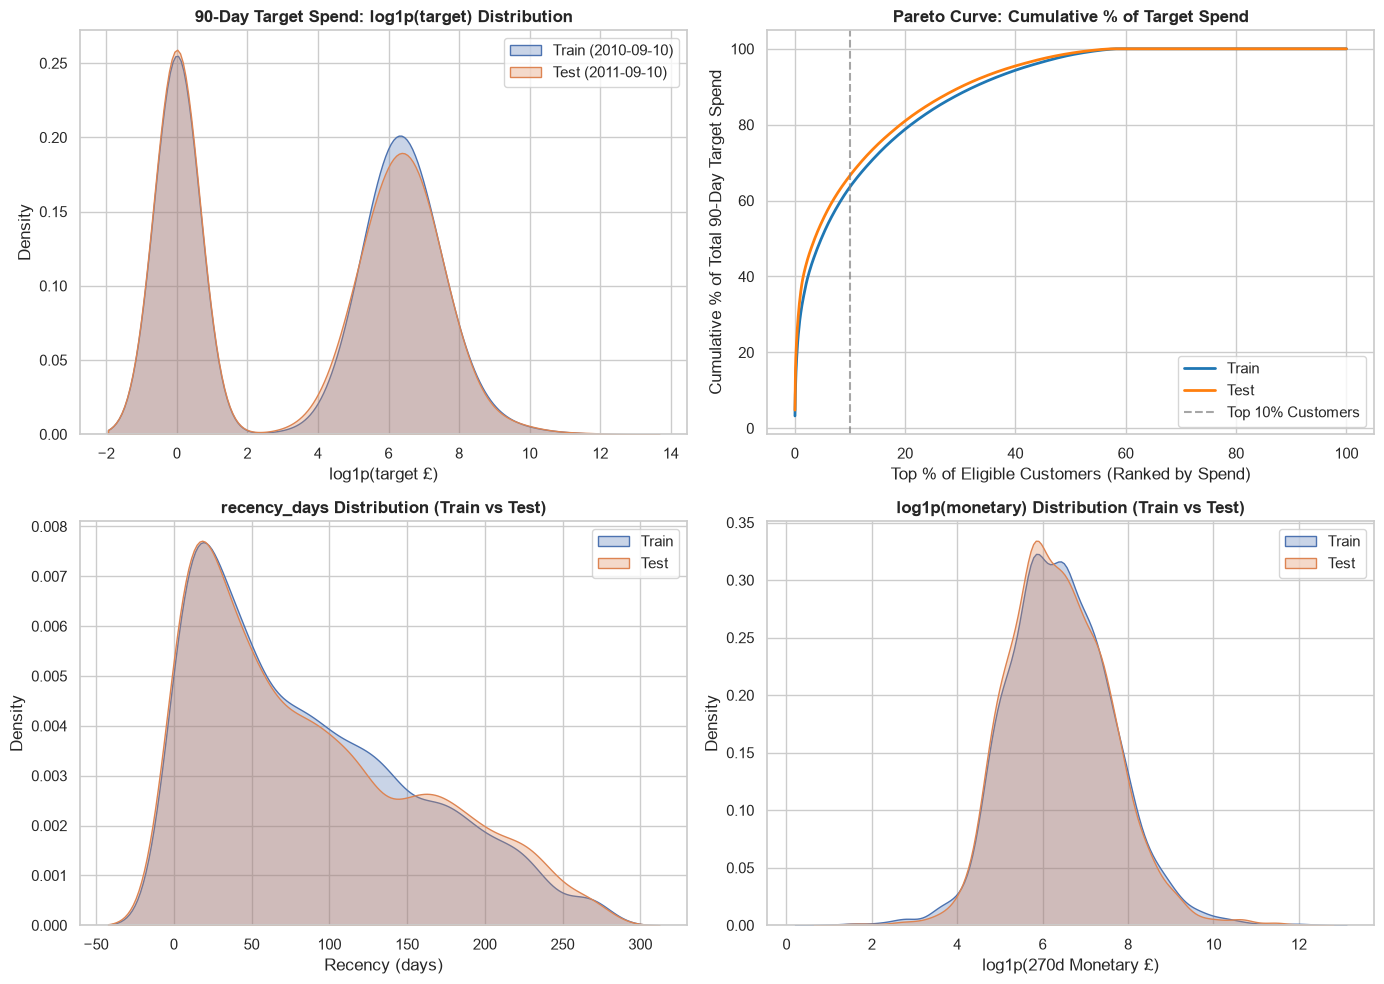

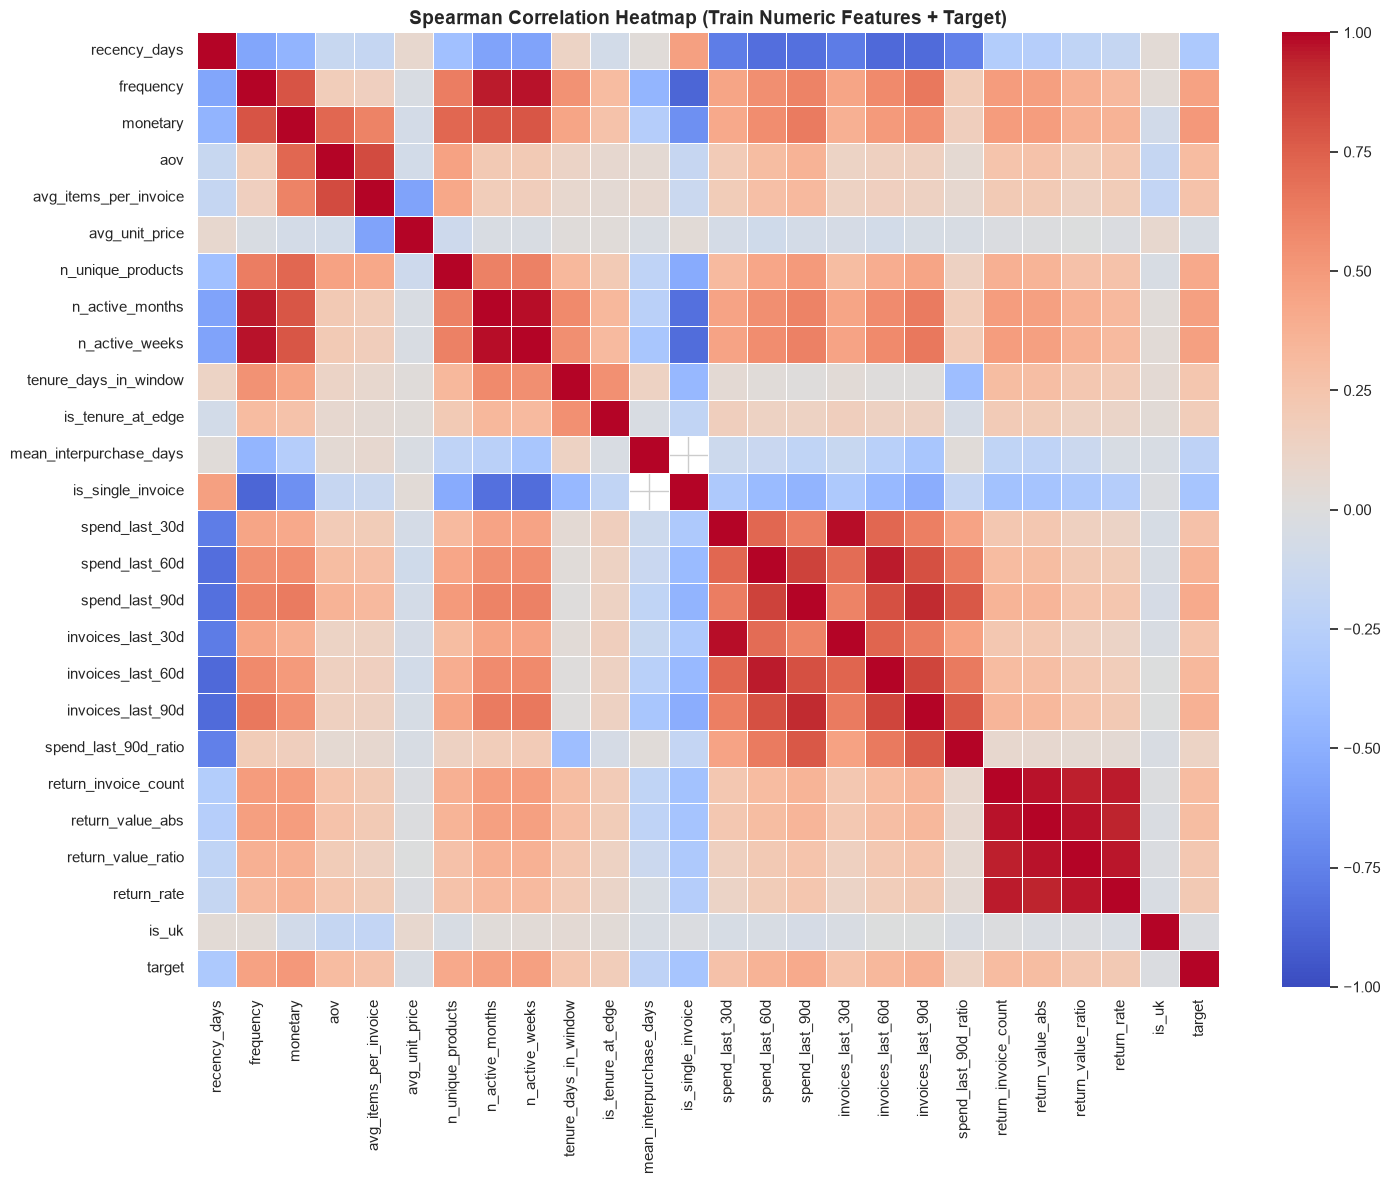


STEP 7.3: TRAIN vs TEST DRIFT AUDIT (KS TEST & PSI)
Features flagged as Notable drift (PSI >= 0.10 or KS >= 0.05 & p < 0.01): 0 / 25


,feature,train_mean,test_mean,train_median,test_median,ks_stat,ks_pvalue,psi,drift_status
0,return_value_ratio,0.024,0.049,0.000,0.000,0.0443,0.003370,0.0101,Stable
1,return_value_abs,42.570,40.416,0.000,0.000,0.0400,0.011061,0.0096,Stable
2,n_unique_products,51.537,48.418,31.000,29.000,0.0377,0.019446,0.0093,Stable
3,mean_interpurchase_days,54.109,56.804,44.256,45.517,0.0374,0.133305,0.0142,Stable
4,return_invoice_count,0.763,0.660,0.000,0.000,0.0333,0.054108,0.0090,Stable
5,return_rate,0.118,0.106,0.000,0.000,0.0315,0.078379,0.0041,Stable
6,avg_unit_price,2.278,2.435,1.863,1.823,0.0280,0.153778,0.0102,Stable
7,recency_days,85.739,86.518,70.499,67.328,0.0276,0.167545,0.0092,Stable
8,tenure_days_in_window,166.522,167.102,178.542,177.619,0.0275,0.170166,0.0199,Stable
9,is_uk,0.923,0.899,1.000,1.000,0.0240,0.304550,0.0071,Stable



Top 8 Countries Share (Train vs Test %):


,train_pct,test_pct
country,,
United Kingdom,92.32,89.92
Germany,1.83,2.23
France,1.05,2.11
Netherlands,0.53,0.22
Spain,0.4,0.65
Belgium,0.37,0.71
Portugal,0.34,0.34
Switzerland,0.34,0.5



STEP 7.4: MISSING VALUES REPORT


,train_nulls,train_null_pct,test_nulls,test_null_pct
mean_interpurchase_days,1290,39.96,1330,41.25


Total columns with zero nulls: 28 / 29


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

sns.set_theme(style="whitegrid")

# =====================================================================
# 7.1 Target Comparison Side by Side (Zero Share, Quantiles, Skew, Pareto)
# =====================================================================
def summarize_target(df_split: pd.DataFrame, name: str) -> dict:
    t = df_split["target"]
    total_rev = t.sum()
    t_sorted = t.sort_values(ascending=False)
    top_1pct_n = max(1, int(np.ceil(0.01 * len(t))))
    top_10pct_n = max(1, int(np.ceil(0.10 * len(t))))
    return {
        "split": name,
        "n_customers": len(t),
        "zero_pct": round((t == 0).mean() * 100, 2),
        "mean": round(t.mean(), 2),
        "q50_median": round(t.quantile(0.50), 2),
        "q75": round(t.quantile(0.75), 2),
        "q90": round(t.quantile(0.90), 2),
        "q95": round(t.quantile(0.95), 2),
        "q99": round(t.quantile(0.99), 2),
        "max": round(t.max(), 2),
        "skewness": round(float(t.skew()), 2),
        "top_1pct_share_pct": round(float(t_sorted.iloc[:top_1pct_n].sum() / total_rev * 100), 2),
        "top_10pct_share_pct": round(float(t_sorted.iloc[:top_10pct_n].sum() / total_rev * 100), 2),
    }

target_eda_df = pd.DataFrame([
    summarize_target(train_df, "T_train (2010-09-10)"),
    summarize_target(test_df, "T_test (2011-09-10)"),
])

print("=" * 70)
print("STEP 7.1: TARGET DISTRIBUTIONS & PARETO CONCENTRATION")
print("=" * 70)
display(target_eda_df)

# =====================================================================
# 7.2 Visualizations: Target, Key Features (Train vs Test) & Correlation Heatmap
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Log1p Target Distribution
sns.kdeplot(np.log1p(train_df["target"]), ax=axes[0, 0], label="Train (2010-09-10)", fill=True, alpha=0.3)
sns.kdeplot(np.log1p(test_df["target"]), ax=axes[0, 0], label="Test (2011-09-10)", fill=True, alpha=0.3)
axes[0, 0].set_title("90-Day Target Spend: log1p(target) Distribution", fontweight="bold")
axes[0, 0].set_xlabel("log1p(target £)")
axes[0, 0].legend()

# Plot 2: Pareto / Lorenz Curve of Target Spend
for label, df_sp, color in [("Train", train_df, "#1f77b4"), ("Test", test_df, "#ff7f0e")]:
    vals = np.sort(df_sp["target"].values)[::-1]
    cum_cust = np.arange(1, len(vals) + 1) / len(vals) * 100
    cum_rev = np.cumsum(vals) / vals.sum() * 100
    axes[0, 1].plot(cum_cust, cum_rev, label=label, linewidth=2, color=color)
axes[0, 1].axvline(10, color="gray", linestyle="--", alpha=0.7, label="Top 10% Customers")
axes[0, 1].set_title("Pareto Curve: Cumulative % of Target Spend", fontweight="bold")
axes[0, 1].set_xlabel("Top % of Eligible Customers (Ranked by Spend)")
axes[0, 1].set_ylabel("Cumulative % of Total 90-Day Target Spend")
axes[0, 1].legend()

# Plot 3: Recency Days Distribution (Train vs Test)
sns.kdeplot(train_df["recency_days"], ax=axes[1, 0], label="Train", fill=True, alpha=0.3)
sns.kdeplot(test_df["recency_days"], ax=axes[1, 0], label="Test", fill=True, alpha=0.3)
axes[1, 0].set_title("recency_days Distribution (Train vs Test)", fontweight="bold")
axes[1, 0].set_xlabel("Recency (days)")
axes[1, 0].legend()

# Plot 4: Log1p Monetary Distribution (Train vs Test)
sns.kdeplot(np.log1p(train_df["monetary"]), ax=axes[1, 1], label="Train", fill=True, alpha=0.3)
sns.kdeplot(np.log1p(test_df["monetary"]), ax=axes[1, 1], label="Test", fill=True, alpha=0.3)
axes[1, 1].set_title("log1p(monetary) Distribution (Train vs Test)", fontweight="bold")
axes[1, 1].set_xlabel("log1p(270d Monetary £)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Spearman Correlation Heatmap (Numeric Features + Target on Train)
numeric_cols = [c for c in FEATURE_COLUMNS if c != "country"]
spearman_mat = train_df[numeric_cols + ["target"]].corr(method="spearman")

plt.figure(figsize=(15, 12))
sns.heatmap(spearman_mat, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=False, linewidths=0.4)
plt.title("Spearman Correlation Heatmap (Train Numeric Features + Target)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# =====================================================================
# 7.3 Train-vs-Test Drift Check (Summary Stats + KS Test + PSI)
# =====================================================================
def compute_psi(expected: pd.Series, actual: pd.Series, n_bins: int = 10) -> float:
    '''Population Stability Index using quantile bins derived from expected (train).'''
    exp_clean = expected.dropna().to_numpy(dtype=float)
    act_clean = actual.dropna().to_numpy(dtype=float)
    quantiles = np.linspace(0, 1, n_bins + 1)
    edges = np.unique(np.quantile(exp_clean, quantiles))
    if len(edges) <= 2:
        # Discrete / binary feature: compare exact unique categories
        cats = np.unique(np.concatenate([exp_clean, act_clean]))
        exp_cnt = np.array([(exp_clean == c).sum() for c in cats], dtype=float)
        act_cnt = np.array([(act_clean == c).sum() for c in cats], dtype=float)
    else:
        edges[0] = -np.inf
        edges[-1] = np.inf
        exp_cnt, _ = np.histogram(exp_clean, bins=edges)
        act_cnt, _ = np.histogram(act_clean, bins=edges)
    exp_pct = np.clip(exp_cnt / len(exp_clean), 1e-6, None)
    act_pct = np.clip(act_cnt / len(act_clean), 1e-6, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

drift_rows = []
for col in numeric_cols:
    tr_s = train_df[col].dropna()
    te_s = test_df[col].dropna()
    ks_res = ks_2samp(tr_s, te_s)
    psi_val = compute_psi(tr_s, te_s)
    drift_flag = "Notable" if (psi_val >= 0.10 or (ks_res.statistic >= 0.05 and ks_res.pvalue < 0.01)) else "Stable"
    drift_rows.append({
        "feature": col,
        "train_mean": round(float(tr_s.mean()), 3),
        "test_mean": round(float(te_s.mean()), 3),
        "train_median": round(float(tr_s.median()), 3),
        "test_median": round(float(te_s.median()), 3),
        "ks_stat": round(float(ks_res.statistic), 4),
        "ks_pvalue": round(float(ks_res.pvalue), 6),
        "psi": round(psi_val, 4),
        "drift_status": drift_flag,
    })

drift_df = pd.DataFrame(drift_rows).sort_values("ks_stat", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("STEP 7.3: TRAIN vs TEST DRIFT AUDIT (KS TEST & PSI)")
print("=" * 70)
print(f"Features flagged as Notable drift (PSI >= 0.10 or KS >= 0.05 & p < 0.01): {(drift_df['drift_status'] == 'Notable').sum()} / {len(drift_df)}")
with pd.option_context("display.max_rows", 30):
    display(drift_df)

# Also check Country distribution shift
country_comp = pd.DataFrame({
    "train_pct": (train_df["country"].value_counts(normalize=True) * 100).round(2),
    "test_pct": (test_df["country"].value_counts(normalize=True) * 100).round(2),
}).fillna(0.0).sort_values("train_pct", ascending=False)
print("\nTop 8 Countries Share (Train vs Test %):")
display(country_comp.head(8))

# =====================================================================
# 7.4 Missing Values Report Per Feature
# =====================================================================
missing_report = pd.DataFrame({
    "train_nulls": train_df.isna().sum(),
    "train_null_pct": (train_df.isna().mean() * 100).round(2),
    "test_nulls": test_df.isna().sum(),
    "test_null_pct": (test_df.isna().mean() * 100).round(2),
})
print("\n" + "=" * 70)
print("STEP 7.4: MISSING VALUES REPORT")
print("=" * 70)
display(missing_report[missing_report["train_nulls"] + missing_report["test_nulls"] > 0])
print(f"Total columns with zero nulls: {(missing_report['train_nulls'] + missing_report['test_nulls'] == 0).sum()} / {len(missing_report)}")

## Step 8: Descriptive RFM Segmentation Snapshot (`2011-12-10`, Full History)

### Why Full History (`lookback_days=None`) Is Valid Here — And Strictly Forbidden for CLV
1. **No Future Target Exists Here (Descriptive vs. Predictive):** In RFM customer segmentation (clustering / rule-based tiers such as *Champions*, *Loyal*, *At Risk*, *Hibernating*), we want a complete snapshot of every active and lapsed customer's lifetime relationship with the business as of the day after the dataset ends (`T_snapshot = 2011-12-10 00:00:00`). Because there is no future target label being predicted from this snapshot, using all 24 months of history creates **zero target leakage** and avoids artificially dropping customers who last bought >270 days ago.
2. **Strict Separation From CLV Modeling:** This `rfm_snapshot` table is **never** passed into the 90-day CLV regression/hurdle models (`train_df` and `test_df` remain strictly restricted to `L = 270` days).
3. **Reusable Pipeline Logic:** Calling the exact same `build_features(..., lookback_days=None)` function guarantees consistent definitions of `recency_days`, `frequency`, `monetary`, and return rates across both segmentation and supervised CLV.

In [10]:
T_SNAPSHOT = pd.Timestamp("2011-12-10 00:00:00")
assert T_SNAPSHOT > DATA_END, f"Snapshot {T_SNAPSHOT} must sit after DATA_END {DATA_END}!"

rfm_snapshot = build_features(
    sales_clean,
    returns_clean,
    cutoff=T_SNAPSHOT,
    lookback_days=None,
)

# Verify full registered sales customer coverage and zero edge-censoring flags
assert len(rfm_snapshot) == sales_clean["Customer ID"].nunique(), "Missing sales customers in snapshot!"
assert (rfm_snapshot["is_tenure_at_edge"] == 0).all(), "is_tenure_at_edge must be 0 when lookback_days=None!"

print("=" * 70)
print("STEP 8 SUMMARY: DESCRIPTIVE RFM SEGMENTATION SNAPSHOT")
print("=" * 70)
print(f"Snapshot Cutoff      : {T_SNAPSHOT} (lookback_days=None, full 24-month history)")
print(f"rfm_snapshot shape   : {rfm_snapshot.shape} (covers all {len(rfm_snapshot):,} registered buyers in sales_clean)")
print(f"Single-invoice share : {rfm_snapshot['is_single_invoice'].mean() * 100:.2f}% ({int(rfm_snapshot['is_single_invoice'].sum()):,} customers)")
print(f"Snapshot total spend : £{rfm_snapshot['monetary'].sum():,.2f}")

print("\nKey RFM & Timing Summary Statistics:")
summary_cols = ["recency_days", "frequency", "monetary", "aov", "tenure_days_in_window", "mean_interpurchase_days", "return_rate"]
display(rfm_snapshot[summary_cols].describe().T[["count", "mean", "std", "min", "50%", "75%", "max"]].round(2))

print("\n5 Sample Rows from rfm_snapshot (Random Seed = 42):")
display(rfm_snapshot[["recency_days", "frequency", "monetary", "aov", "tenure_days_in_window", "mean_interpurchase_days", "return_rate", "country"]].sample(5, random_state=42))

STEP 8 SUMMARY: DESCRIPTIVE RFM SEGMENTATION SNAPSHOT
Snapshot Cutoff      : 2011-12-10 00:00:00 (lookback_days=None, full 24-month history)
rfm_snapshot shape   : (5852, 26) (covers all 5,852 registered buyers in sales_clean)
Single-invoice share : 27.67% (1,619 customers)
Snapshot total spend : £16,783,959.54

Key RFM & Timing Summary Statistics:


,count,mean,std,min,50%,75%,max
recency_days,5852.0,200.26,208.54,0.47,95.36,379.34,738.55
frequency,5852.0,6.25,12.75,1.00,3.00,7.00,373.00
monetary,5852.0,2868.07,14100.43,2.90,855.58,2236.86,580987.04
aov,5852.0,363.43,483.17,2.90,277.65,410.10,14844.77
tenure_days_in_window,5852.0,473.99,223.19,0.49,529.43,666.59,738.68
mean_interpurchase_days,4233.0,103.39,99.11,0.00,72.87,130.96,714.15
return_rate,5852.0,0.11,0.16,0.00,0.00,0.20,0.80



5 Sample Rows from rfm_snapshot (Random Seed = 42):


,recency_days,frequency,monetary,aov,tenure_days_in_window,mean_interpurchase_days,return_rate,country
Customer ID,,,,,,,,
15684,547.214583,3,173.95,57.983333,735.324306,94.054861,0.500000,United Kingdom
15271,7.409028,24,4528.54,188.689167,491.377083,21.042089,0.076923,United Kingdom
15394,9.507639,11,5286.80,480.618182,724.204861,71.469722,0.153846,United Kingdom
12369,413.449306,3,1511.15,503.716667,641.660417,114.105556,0.000000,Austria
13443,448.478472,6,1269.37,211.561667,677.437500,45.791806,0.142857,United Kingdom


## Step 10: Export Parquet Feature Tables & Verify `src/features.py`

### Why Export to `data/processed/features/` and Share `src/features.py`?
1. **Training–Serving & Notebook–Module Parity:** Exporting `build_features` and `build_target` into `src/features.py` ensures downstream modeling notebooks, unit tests (`tests/test_features.py`), CI pipelines, and future inference jobs run the **exact same code path** — zero copy-paste skew.
2. **Parquet Preservation:** Keeps `Customer ID` index, `Int64`, nullable `string`, `float64`, and `NaN`s intact with fast Snappy compression.

In [11]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import build_features as mod_build_features, build_target as mod_build_target

# Verify src/features.py produces identical output to notebook functions
mod_train_feat = mod_build_features(sales_clean, returns_clean, cutoff=T_TRAIN, lookback_days=LOOKBACK_DAYS)
mod_train_tg = mod_build_target(sales_clean, returns_clean, cutoff=T_TRAIN, horizon_days=HORIZON_DAYS, eligible_ids=mod_train_feat.index)
pd.testing.assert_frame_equal(train_df, mod_train_feat.join(mod_train_tg))

FEATURES_DIR.mkdir(parents=True, exist_ok=True)

export_map = {
    "features_train_2010-09-10": train_df,
    "features_test_2011-09-10": test_df,
    "rfm_snapshot_2011-12-10": rfm_snapshot,
}

# Verify train and test schemas match 100%
assert list(train_df.columns) == list(test_df.columns), "Train/test schema mismatch!"
assert (train_df.dtypes == test_df.dtypes).all(), "Train/test dtype mismatch!"

export_summary = []
for name, df_out in export_map.items():
    out_path = FEATURES_DIR / f"{name}.parquet"
    df_out.to_parquet(out_path, index=True)
    reloaded = pd.read_parquet(out_path)
    assert reloaded.shape == df_out.shape, f"Round-trip shape mismatch for {name}!"
    assert reloaded.index.name == "Customer ID", f"Index name lost for {name}!"
    export_summary.append({
        "artifact": f"{name}.parquet",
        "rows": len(reloaded),
        "cols": reloaded.shape[1],
        "size_mb": round(out_path.stat().st_size / (1024 * 1024), 3),
        "path": str(out_path.relative_to(PROJECT_ROOT)),
    })

print("=" * 70)
print("STEP 10 SUMMARY: PARQUET EXPORTS & src/features.py PARITY VERIFIED")
print("=" * 70)
display(pd.DataFrame(export_summary))

print("\n5 Sample Rows Reloaded From features_train_2010-09-10.parquet (Random Seed = 42):")
display(pd.read_parquet(FEATURES_DIR / "features_train_2010-09-10.parquet").sample(5, random_state=42))

STEP 10 SUMMARY: PARQUET EXPORTS & src/features.py PARITY VERIFIED


,artifact,rows,cols,size_mb,path
0,features_train_2010-09-10.parquet,3228,29,0.284,data\processed\features\features_train_2010-09...
1,features_test_2011-09-10.parquet,3224,29,0.282,data\processed\features\features_test_2011-09-...
2,rfm_snapshot_2011-12-10.parquet,5852,26,0.471,data\processed\features\rfm_snapshot_2011-12-1...



5 Sample Rows Reloaded From features_train_2010-09-10.parquet (Random Seed = 42):


,recency_days,frequency,monetary,aov,avg_items_per_invoice,avg_unit_price,n_unique_products,n_active_months,n_active_weeks,tenure_days_in_window,is_tenure_at_edge,mean_interpurchase_days,is_single_invoice,spend_last_30d,spend_last_60d,spend_last_90d,invoices_last_30d,invoices_last_60d,invoices_last_90d,spend_last_90d_ratio,return_invoice_count,return_value_abs,return_value_ratio,return_rate,is_uk,country,target,target_net,target_active
Customer ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
13225,18.443056,7,8199.81,1171.401429,485.000000,2.415261,47,6,6,266.618750,1,41.362616,0,1165.14,1165.14,2357.74,1,1,2,0.287536,0,0.0,0.0,0.0,1,United Kingdom,1596.42,1596.42,1
16219,44.511111,1,40.80,40.800000,48.000000,0.850000,1,1,1,44.511111,0,NaN,1,0.00,40.80,40.80,0,1,1,1.000000,0,0.0,0.0,0.0,1,United Kingdom,0.00,0.00,0
12960,27.518750,3,1145.87,381.956667,409.333333,0.933119,43,3,3,205.436111,0,88.958681,0,412.30,412.30,412.30,1,1,1,0.359814,0,0.0,0.0,0.0,1,United Kingdom,176.20,176.20,1
18001,90.504861,1,101.10,101.100000,62.000000,1.630645,19,1,1,90.504861,0,NaN,1,0.00,0.00,0.00,0,0,0,0.000000,0,0.0,0.0,0.0,1,United Kingdom,231.31,231.31,1
15288,139.465972,2,757.61,378.805000,181.000000,2.092845,43,2,2,209.356250,0,69.890278,0,0.00,0.00,0.00,0,0,0,0.000000,0,0.0,0.0,0.0,1,United Kingdom,642.40,642.40,1


---

## Phase 3 Summary (For Interview Defense & Project README)

### 1. Cutoff Cohorts & Zero-Target Share

| Artifact | Cutoff $T$ | Lookback | Eligible Customers | Zero-Target Share | Total Target Spend (£) | Target Skewness | Top 1% / Top 10% Spend Share |
| :--- | :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **`features_train_2010-09-10.parquet`** | `2010-09-10` | `270d` | **3,228** | **41.60%** (`1,343` zeros) | `£2,430,069.08` | `16.82` | `29.79%` / `63.63%` |
| **`features_test_2011-09-10.parquet`** | `2011-09-10` | `270d` | **3,224** | **42.25%** (`1,362` zeros) | `£2,585,609.91` | `20.95` | `35.31%` / `66.64%` |
| **`rfm_snapshot_2011-12-10.parquet`** | `2011-12-10` | Full 24m (`None`) | **5,852** | *Descriptive only* | *N/A* | *N/A* | *N/A* |

*(Optional Step 9 deduplication sensitivity check was skipped per project scope.)*

---

### 2. Engineered Feature Set (26 Features + 3 Target Columns)
- **Core RFM (`3`)**: `recency_days`, `frequency`, `monetary` — capture recency decay, habit count, and gross 270d spending capacity.
- **Behavior (`6`)**: `aov`, `avg_items_per_invoice`, `avg_unit_price`, `n_unique_products`, `n_active_months`, `n_active_weeks` — capture basket size, weighted unit price, catalog breadth, and weekly/monthly purchase regularity.
- **Timing (`4`)**: `tenure_days_in_window`, `is_tenure_at_edge` (flags left-censoring within 7d of `T - 270d`), `mean_interpurchase_days` (intentionally `NaN` for single-invoice accounts), `is_single_invoice`.
- **Recent Momentum (`7`)**: `spend_last_30d/60d/90d`, `invoices_last_30d/60d/90d`, `spend_last_90d_ratio` — measure short-to-medium acceleration directly preceding $T$.
- **Historical Returns (`4`)**: `return_invoice_count`, `return_value_abs`, `return_value_ratio`, `return_rate` — strictly from `[T - L, T)` as return-friction/churn signals.
- **Geography (`2`)**: `is_uk`, `country` (latest at $T$, keeping `'Unspecified'` explicit).
- **Targets (`3`)**: `target` (gross 90d sales `>= 0`), `target_net` (`sales + returns` sensitivity column), `target_active` (`1` if `target > 0` else `0`).

---

### 3. Leakage Audit & Drift Findings
- **Leakage Audit Passed (`0` violations)**: All feature timestamps strictly `< T` (max train `2010-09-09 20:03`, max test `2011-09-09 16:36`); all target timestamps strictly inside `[T, T + 90d)` (excluding partial final day `2011-12-09`); maximum `|Spearman|` with `target` is `0.5315` (`monetary`).
- **Drift Findings (`0 / 25` notable drift)**: Fixing `L = 270` days and matching Sep 10 cutoffs eliminated history-length and seasonal drift across all 25 numeric features (`PSI` ranged `0.0000–0.0199`; `KS <= 0.0443`). Minor business shifts observed:
  1. `return_value_ratio` mean rose (`0.024 -> 0.049`, `KS = 0.0443, p = 0.0034`) due to a small set of high-value 2011 B2B cancellations.
  2. Non-UK export share grew slightly (`is_uk` `92.32% -> 89.92%`), led by France (`1.05% -> 2.11%`) and Germany (`1.83% -> 2.23%`).

---

### 4. Known Limitations (For README & Downstream Modeling)
1. **Lookback Window Scope Boundary (`L = 270d`)**: At `T_test`, `2,023` lapsed accounts active before `2010-12-14` were excluded (`413` of whom reactivated during Q4 2011 — primarily annual Christmas-only buyers), plus `33` returns-only accounts and `594` cold-start new buyers (`922` at `T_train`). Our CLV model scores **active registered buyers within a 9-month lookback** rather than cold-start or annual-only dormant buyers.
2. **Missing Inter-Purchase Intervals (`NaN`)**: `mean_interpurchase_days` is `NaN` for single-invoice customers (`39.96%` train, `41.25%` test). Linear models must impute inside `sklearn` `Pipeline`s alongside `is_single_invoice`; tree models can consume `NaN` directly.
3. **Extreme Target Right-Skewness & Zero-Inflation**: `~42%` zero targets and `skew = 16.8–21.0` (top 1% = `30–35%` of spend) mean naive MSE loss will overfit wholesale whales; downstream Phase 4 modeling should compare `log1p(target)`, Tweedie regression, and two-stage Hurdle architectures.
4. **Collinear Predictors**: Cumulative features (`monetary`, `spend_last_90d`, `frequency`, `n_active_weeks`) are intentionally preserved for tree ensembles and must be regularized or subsetted inside linear baselines.
5. **Descriptive Snapshot Separation**: `rfm_snapshot_2011-12-10.parquet` (`5,852` customers, `lookback_days=None`) is strictly for descriptive CRM segmentation and must never be used to train or validate the 90-day CLV model.